# Higher-Dimensional MDI-QKD under Channel Noise, d = 2–7

Circuit-level simulation of measurement-device-independent QKD with qudits in PennyLane.

- **Encoding:** Alice and Bob each prepare a qudit in the computational (Z) basis or the
  discrete-Fourier (X) basis, which are mutually unbiased bases (MUBs).
- **Channel noise:** `qml.DepolarizingChannel` on the physical qubits carrying each qudit, applied after
  state preparation and before the measurement (`default.mixed` density-matrix device).
- **Measurement:** Charlie performs a generalised Bell-state measurement (BSM) that resolves the $d$
  Bell states with $l = 0$, so the success probability is $P_S = 1/d$. He announces the shift $m$,
  and Bob corrects with $b_{\rm corr} = (b - m) \bmod d$.
- **Key rate:** $r_d(Q) = \log_2 d - 2H_d(Q)$ per sifted symbol. The total rate per transmitted signal is
  $R = \tfrac12 \cdot \tfrac1d \cdot r_d(Q)$.
- **Attack model:** intercept-resend on Alice's channel, with expected QSER $\tfrac12\cdot\tfrac{d-1}{d}$.

Qudits are mapped onto qubits as follows: $d=2$ uses one qubit, $d=3$ two (padded), $d=4$ two
(exact), and $d=5,6,7$ three (padded). Population that noise pushes into unused padding states is
treated as a detected erasure (a lost round), not as a symbol error.

| Section | Content |
|---|---|
| 0 | Shared functions and parameters |
| 1 | Concept visualisations: MUBs, Bell bases, BSM outcomes, entanglement witness |
| 2 | d = 2 (qubit) |
| 3 | d = 3 (qutrit) |
| 4 | d = 4 (ququart) |
| 5 | d = 5, 6, 7 (padded qudits) |
| 6 | Cross-dimension analysis: total key rate, crossovers, thresholds, security margin |

In [ ]:
#Install
!pip install pennylane scipy -q

In [ ]:
#Import

import random
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pennylane as qml
from scipy.optimize import brentq

warnings.filterwarnings("ignore")
print("PennyLane version:", qml.__version__)

PennyLane version: 0.45.1


## 0. Shared functions and parameters

Binary entropy: $H_2(x) = -x\log_2 x - (1-x)\log_2(1-x)$

$d$-ary entropy: $H_d(Q) = -(1-Q)\log_2(1-Q) - Q\log_2\frac{Q}{d-1}$

Secret key rate per sifted symbol: $r_d(Q) = \log_2 d - 2H_d(Q)$. Zero-rate threshold $e^*(d)$: $\log_2 d = 2H_d(e^*)$.

Total key rate per transmitted signal: $R_{\rm total} = \tfrac12 \cdot P_S \cdot r_d(Q)$ with $P_S = 1/d$.

Channel transmittance (Beer–Lambert): $\eta = 10^{-\alpha L/10}$.

In [ ]:
# Physical parameters
ALPHA_DB = 0.2     # fibre loss coefficient (dB/km)
ETA_DET  = 0.145   # detector efficiency
L_A      = 25      # Alice -> Charlie distance (km)
L_B      = 25      # Bob -> Charlie distance (km)


def channel_efficiency(L):
    """Fibre transmittance for length L (km)."""
    return 10 ** (-ALPHA_DB * L / 10)


def H2(x):
    """Binary entropy (bits)."""
    if x <= 0 or x >= 1:
        return 0.0
    return float(-x * np.log2(x) - (1 - x) * np.log2(1 - x))


def H_d(Q, d):
    """d-ary entropy with errors spread uniformly over the d-1 wrong symbols."""
    if Q <= 0:
        return 0.0
    if Q >= 1:
        return float(np.log2(d))
    return float(-(1 - Q) * np.log2(1 - Q) - Q * np.log2(Q / (d - 1)))


def r_d_raw(Q, d):
    """Unclamped key rate r_d(Q) = log2(d) - 2 H_d(Q)."""
    return float(np.log2(d) - 2 * H_d(Q, d))


def r_d_formula(Q, d):
    """Secret key rate per sifted symbol, clamped at zero."""
    return max(0.0, r_d_raw(Q, d))


def R_total_formula(Q, d, ps=None):
    """Total key rate per transmitted signal: (1/2) * P_S * r_d(Q), default P_S = 1/d."""
    ps = 1.0 / d if ps is None else ps
    return 0.5 * ps * r_d_formula(Q, d)


def zero_rate_threshold(d):
    """QSER at which r_d(Q) = 0 (Brent's method)."""
    return brentq(lambda Q: r_d_raw(Q, d), 1e-9, 0.499)


def dft_basis(d):
    """Rows are the Fourier (X-basis) states |phi_j> = (1/sqrt d) sum_k w^{jk} |k>."""
    w = np.exp(2j * np.pi / d)
    return np.array([[w ** (j * k) for k in range(d)] for j in range(d)], dtype=complex) / np.sqrt(d)


def bell_d_vec(l, m, d):
    """Generalised Bell state |Psi_{l,m}> = (1/sqrt d) sum_k w^{lk} |k>|(k+m) mod d>."""
    w = np.exp(2j * np.pi / d)
    v = np.zeros(d * d, dtype=complex)
    for k in range(d):
        v[k * d + (k + m) % d] += w ** (l * k)
    return v / np.sqrt(d)


def build_bell_list(d):
    """All d^2 Bell states as (l, m, vector), ordered m-major."""
    return [(l, m, bell_d_vec(l, m, d)) for m in range(d) for l in range(d)]


def correlation_witness(joint_vec, d, mode="comp"):
    """
    Dual-MUB witness on a d^2 joint state vector.
    mode='comp': C_Z = P(a = b) in the computational basis.
    mode='had' : C_X = P(a + b = 0 mod d) in the Fourier basis.
    """
    if mode == "comp":
        basis = np.eye(d, dtype=complex)
        pairs = [(j, j) for j in range(d)]
    else:
        basis = dft_basis(d)
        pairs = [(j, (-j) % d) for j in range(d)]
    p = 0.0
    for j1, j2 in pairs:
        proj = np.kron(basis[j1, :], basis[j2, :])
        p += abs(np.vdot(proj, joint_vec)) ** 2
    return float(p)


print(f"eta({L_A} km) = {channel_efficiency(L_A):.4f}")
print("Zero-rate thresholds e*(d):", {d: f"{zero_rate_threshold(d)*100:.2f}%" for d in range(2, 8)})

eta(25 km) = 0.3162
Zero-rate thresholds e*(d): {2: '11.00%', 3: '15.95%', 4: '18.93%', 5: '20.99%', 6: '22.52%', 7: '23.72%'}


## 1. Concept visualisations

### 1.1 Mutually unbiased bases
For the computational basis $\{|k\rangle\}$ and the Fourier basis $\{|\varphi_j\rangle\}$,
$|\langle k|\varphi_j\rangle|^2 = 1/d$ for every pair. A state prepared in one basis therefore gives a
uniformly random outcome when measured in the other, which is what makes a wrong-basis
measurement detectable.

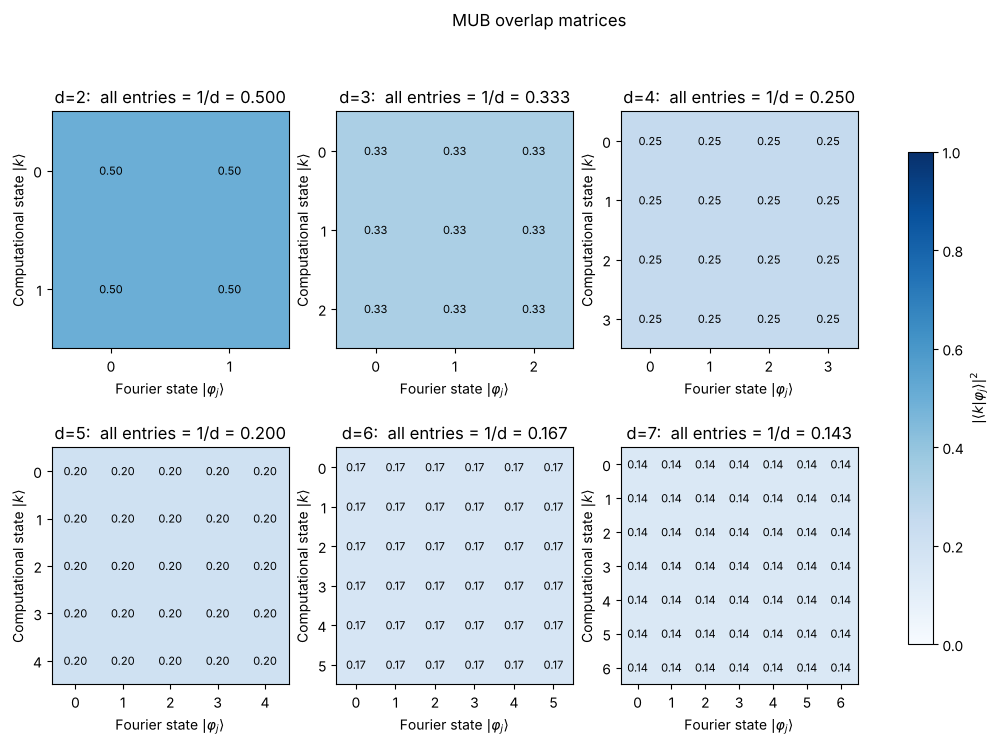

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for ax, d in zip(axes.flat, range(2, 8)):
    overlap = np.abs(np.eye(d) @ dft_basis(d).T) ** 2
    im = ax.imshow(overlap, vmin=0, vmax=1, cmap="Blues")
    for i in range(d):
        for j in range(d):
            ax.text(j, i, f"{overlap[i, j]:.2f}", ha="center", va="center", fontsize=8)
    ax.set_title(f"d={d}:  all entries = 1/d = {1/d:.3f}")
    ax.set_xlabel(r"Fourier state $|\varphi_j\rangle$")
    ax.set_ylabel(r"Computational state $|k\rangle$")
    ax.set_xticks(range(d)); ax.set_yticks(range(d))
fig.colorbar(im, ax=axes, shrink=0.8, label=r"$|\langle k|\varphi_j\rangle|^2$")
plt.suptitle("MUB overlap matrices")
plt.show()

### 1.2 Fourier-basis phases
Phase $\arg\langle k|\varphi_j\rangle = 2\pi jk/d$ of each amplitude. The magnitudes are all equal
(§1.1), so the basis states differ only in these phases.

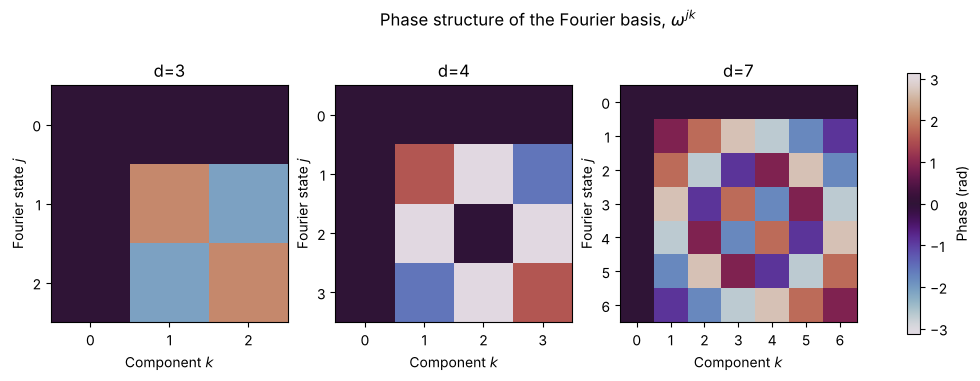

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, d in zip(axes, [3, 4, 7]):
    phases = np.angle(dft_basis(d))
    im = ax.imshow(phases, cmap="twilight", vmin=-np.pi, vmax=np.pi)
    ax.set_title(f"d={d}")
    ax.set_xlabel("Component $k$")
    ax.set_ylabel(r"Fourier state $j$")
    ax.set_xticks(range(d)); ax.set_yticks(range(d))
fig.colorbar(im, ax=axes, shrink=0.85, label="Phase (rad)")
plt.suptitle(r"Phase structure of the Fourier basis, $\omega^{jk}$")
plt.show()

### 1.3 Generalised Bell basis
The $d^2$ states $|\Psi_{l,m}\rangle$ form an orthonormal basis, so their Gram matrix
$|\langle\Psi_i|\Psi_j\rangle|^2$ is the identity. Only the $d$ states with $l=0$ (highlighted) can be
resolved by Charlie, which gives $P_S = 1/d$.

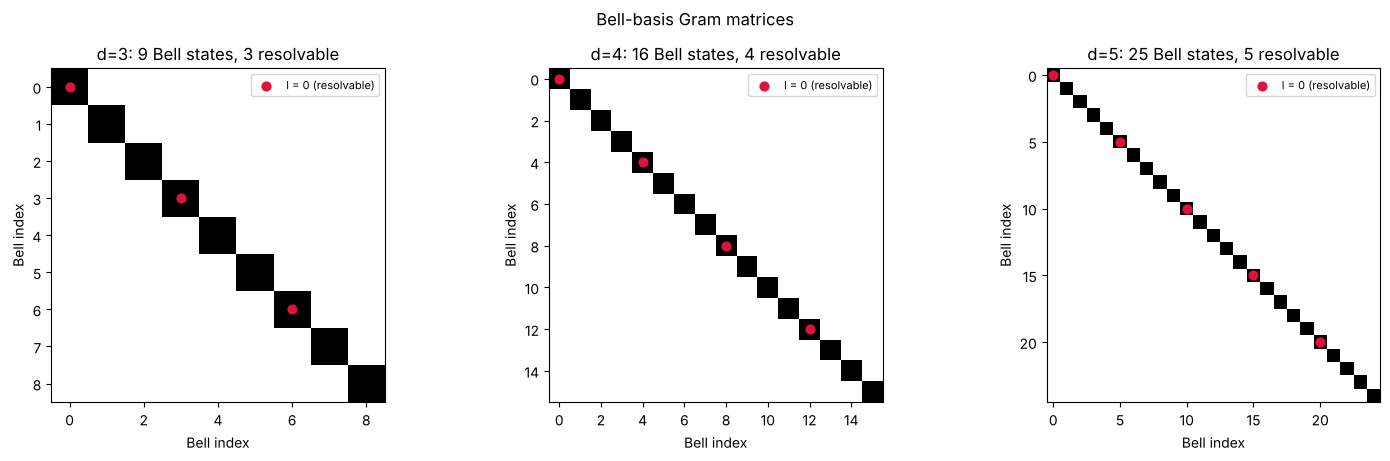

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
for ax, d in zip(axes, [3, 4, 5]):
    bl = build_bell_list(d)
    gram = np.array([[abs(np.vdot(v1, v2)) ** 2 for (_, _, v2) in bl] for (_, _, v1) in bl])
    ax.imshow(gram, cmap="Greys", vmin=0, vmax=1)
    dist = [i for i, (l, m, _) in enumerate(bl) if l == 0]
    ax.scatter(dist, dist, s=40, color="crimson", label="l = 0 (resolvable)")
    ax.set_title(f"d={d}: {d*d} Bell states, {d} resolvable")
    ax.set_xlabel("Bell index"); ax.set_ylabel("Bell index")
    ax.legend(loc="upper right", fontsize=8)
plt.suptitle("Bell-basis Gram matrices")
plt.tight_layout()
plt.show()

### 1.4 BSM outcomes and the correction rule
Born-rule probability that Charlie announces shift $m$ for product inputs, with no noise.

- **Z–Z inputs:** $|a\rangle|b\rangle$ projects onto $|\Psi_{0,m}\rangle$ only for $m = (b-a) \bmod d$, with
  probability $1/d$. Bob's correction $b - m$ therefore recovers $a$ exactly.
- **X–X inputs:** $|\varphi_{j_a}\rangle|\varphi_{j_b}\rangle$ produces an $l=0$ click only when
  $j_a + j_b \equiv 0 \pmod d$, and then every $m$ is equally likely. Because $m$ carries no
  information about the symbols in that case, key bits come from Z-basis rounds only.

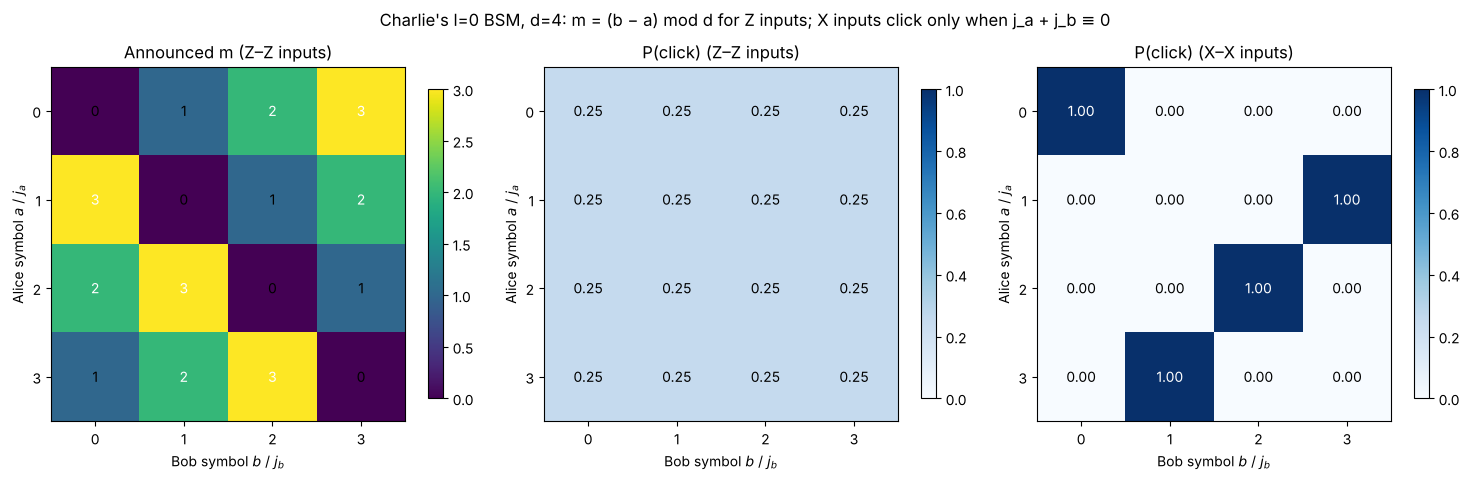

X–X example (j_a=1, j_b=3): P(m) = [0.25 0.25 0.25 0.25]  -> m uniform, uninformative


In [ ]:
def bsm_click_probs(vec_a, vec_b, d):
    """P(announce m) over the l=0 Bell states for a product input."""
    joint = np.kron(vec_a, vec_b)
    return np.array([abs(np.vdot(bell_d_vec(0, m, d), joint)) ** 2 for m in range(d)])


d_demo = 4
F = dft_basis(d_demo)
I = np.eye(d_demo)
m_map  = np.zeros((d_demo, d_demo))
p_zz   = np.zeros((d_demo, d_demo))
p_xx   = np.zeros((d_demo, d_demo))
for a in range(d_demo):
    for b in range(d_demo):
        pz = bsm_click_probs(I[a], I[b], d_demo)
        m_map[a, b] = int(np.argmax(pz))
        p_zz[a, b]  = pz.sum()
        p_xx[a, b]  = bsm_click_probs(F[a], F[b], d_demo).sum()

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
panels = [(m_map, "Announced m (Z–Z inputs)", "viridis", (0, d_demo - 1), "{:.0f}"),
          (p_zz,  "P(click) (Z–Z inputs)",    "Blues",   (0, 1), "{:.2f}"),
          (p_xx,  "P(click) (X–X inputs)",    "Blues",   (0, 1), "{:.2f}")]
for ax, (data, title, cmap, lim, fmt) in zip(axes, panels):
    im = ax.imshow(data, cmap=cmap, vmin=lim[0], vmax=lim[1])
    for i in range(d_demo):
        for j in range(d_demo):
            ax.text(j, i, fmt.format(data[i, j]), ha="center", va="center", fontsize=10,
                    color="white" if data[i, j] > (lim[1] * 0.6) else "black")
    ax.set_title(title)
    ax.set_xlabel("Bob symbol $b$ / $j_b$"); ax.set_ylabel("Alice symbol $a$ / $j_a$")
    ax.set_xticks(range(d_demo)); ax.set_yticks(range(d_demo))
    fig.colorbar(im, ax=ax, shrink=0.8)
plt.suptitle(f"Charlie's l=0 BSM, d={d_demo}: m = (b − a) mod d for Z inputs; X inputs click only when j_a + j_b ≡ 0")
plt.tight_layout()
plt.show()

xx_m = bsm_click_probs(F[1], F[d_demo - 1], d_demo)
print(f"X–X example (j_a=1, j_b={d_demo-1}): P(m) = {np.round(xx_m, 4)}  -> m uniform, uninformative")

### 1.5 Entanglement verification: dual-MUB correlation witness
Resource state $|\Psi_{00}\rangle = \frac{1}{\sqrt d}\sum_k |k\rangle|k\rangle$.

- $C_Z = P(a=b)$ in the computational basis.
- $C_X = P(a+b \equiv 0 \bmod d)$ in the Fourier basis.

A separable state cannot be perfectly correlated in two MUBs at once; its best value is
$C_X \le 1/d$. Measuring $C_Z = C_X = 1$ therefore certifies entanglement.

 d  C_Z (entangled)  C_X (entangled)  C_X (separable)    1/d  Entangled
 2           1.0000           1.0000           0.5000 0.5000       True
 3           1.0000           1.0000           0.3333 0.3333       True
 4           1.0000           1.0000           0.2500 0.2500       True
 5           1.0000           1.0000           0.2000 0.2000       True
 6           1.0000           1.0000           0.1667 0.1667       True
 7           1.0000           1.0000           0.1429 0.1429       True


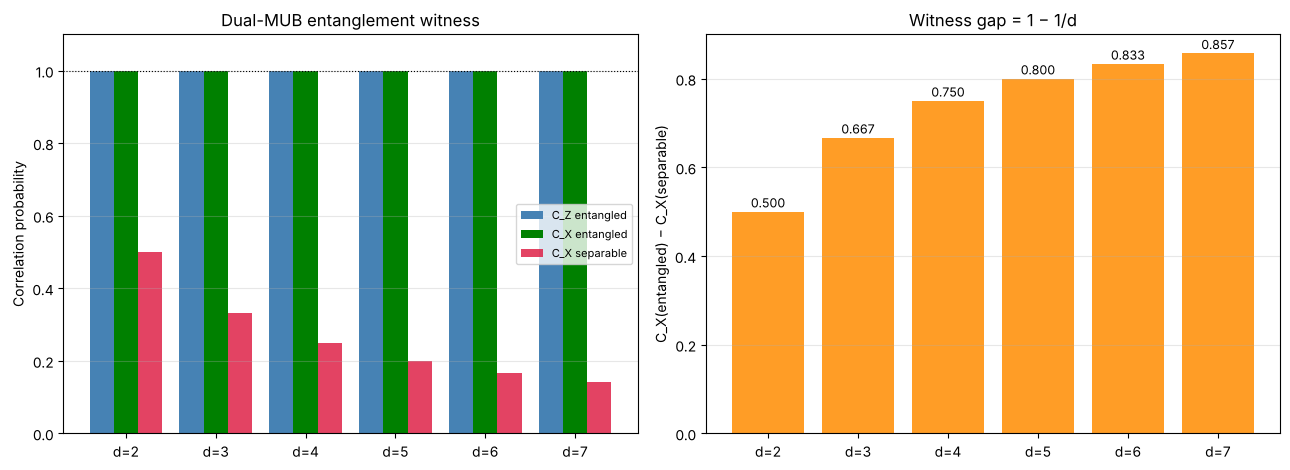

In [ ]:
witness_rows = []
for d in range(2, 8):
    ent_vec = np.zeros(d * d, dtype=complex)
    for k in range(d):
        ent_vec[k * d + k] = 1.0 / np.sqrt(d)
    cz = correlation_witness(ent_vec, d, "comp")
    cx = correlation_witness(ent_vec, d, "had")
    cx_sep = []
    for k in range(d):
        sep = np.zeros(d * d, dtype=complex)
        sep[k * d + k] = 1.0
        cx_sep.append(correlation_witness(sep, d, "had"))
    witness_rows.append({"d": d, "C_Z (entangled)": cz, "C_X (entangled)": cx,
                         "C_X (separable)": float(np.mean(cx_sep)), "1/d": 1 / d,
                         "Entangled": (cz > 0.99) and (cx > 0.99)})
df_witness = pd.DataFrame(witness_rows)
print(df_witness.to_string(index=False, float_format="{:.4f}".format))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
x = np.arange(len(df_witness)); w = 0.27
ax = axes[0]
ax.bar(x - w, df_witness["C_Z (entangled)"], w, label="C_Z entangled", color="steelblue")
ax.bar(x,     df_witness["C_X (entangled)"], w, label="C_X entangled", color="green")
ax.bar(x + w, df_witness["C_X (separable)"], w, label="C_X separable", color="crimson", alpha=0.8)
ax.set_xticks(x); ax.set_xticklabels([f"d={d}" for d in df_witness["d"]])
ax.set_ylabel("Correlation probability"); ax.set_ylim(0, 1.1)
ax.axhline(1.0, color="black", lw=0.8, ls=":")
ax.set_title("Dual-MUB entanglement witness")
ax.legend(fontsize=8); ax.grid(alpha=0.3, axis="y")

ax = axes[1]
gap = df_witness["C_X (entangled)"] - df_witness["C_X (separable)"]
bars = ax.bar(x, gap, color="darkorange", alpha=0.85)
for b, g in zip(bars, gap):
    ax.text(b.get_x() + b.get_width() / 2, g + 0.01, f"{g:.3f}", ha="center", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels([f"d={d}" for d in df_witness["d"]])
ax.set_ylabel("C_X(entangled) − C_X(separable)")
ax.set_title("Witness gap = 1 − 1/d")
ax.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.show()

## 2. d = 2 (qubit) MDI-QKD

BB84 states: $|0\rangle, |1\rangle$ (Z basis) and $|\pm\rangle = (|0\rangle \pm |1\rangle)/\sqrt2$ (X basis).
Charlie resolves the $l=0$ Bell states $|\Phi^+\rangle$ ($m=0$) and $|\Psi^+\rangle$ ($m=1$), so $P_S = 1/2$.
Key rate (Shor–Preskill): $r_2(Q) = \max\{0,\, 1 - 2H_2(Q)\}$.

In [ ]:
N_D2       = 2000   # protocol rounds per run
N_NOISE_D2 = 10     # noise levels in the sweep

np.random.seed(42)
random.seed(42)

dev_d2 = qml.device("default.mixed", wires=2)


def prepare_bb84(basis, bit, wire):
    """Prepare a BB84 state on `wire`."""
    if basis == "Z":
        if bit == 1:
            qml.PauliX(wires=wire)                 # |1>
    else:
        if bit == 0:
            qml.Hadamard(wires=wire)               # |+>
        else:
            qml.PauliX(wires=wire)
            qml.Hadamard(wires=wire)               # |->


@qml.qnode(dev_d2)
def prepare_pair_d2(a_basis, a_bit, b_basis, b_bit, Q_noise=0.0):
    """Joint density matrix after preparation and the depolarizing channel."""
    prepare_bb84(a_basis, a_bit, 0)
    prepare_bb84(b_basis, b_bit, 1)
    if Q_noise > 0:
        qml.DepolarizingChannel(Q_noise, wires=0)   # Alice -> Charlie
        qml.DepolarizingChannel(Q_noise, wires=1)   # Bob -> Charlie
    return qml.density_matrix(wires=[0, 1])


# l = 0 Bell states: m=0 -> Phi+, m=1 -> Psi+
BELL_L0_D2 = [
    (0, np.array([1, 0, 0, 1], dtype=complex) / np.sqrt(2)),
    (1, np.array([0, 1, 1, 0], dtype=complex) / np.sqrt(2)),
]


def bsm_probabilities_d2(a_basis, a_bit, b_basis, b_bit, Q_noise=0.0):
    """Born-rule probabilities [P(m=0), P(m=1)] on the joint state."""
    rho = prepare_pair_d2(a_basis, a_bit, b_basis, b_bit, Q_noise=Q_noise)
    probs = np.array([float(np.real(np.vdot(bs, rho @ bs))) for (_, bs) in BELL_L0_D2])
    return np.clip(probs, 0.0, None)


def charlie_bsm_d2(a_basis, a_bit, b_basis, b_bit, Q_noise=0.0):
    """Sample one BSM; returns m in {0,1} or None (no click)."""
    probs = bsm_probabilities_d2(a_basis, a_bit, b_basis, b_bit, Q_noise=Q_noise)
    p_success = probs.sum()
    if random.random() > p_success:
        return None
    return int(np.random.choice([0, 1], p=probs / p_success))


for a, b in [(0, 1), (1, 0), (0, 0), (1, 1)]:
    p = bsm_probabilities_d2("Z", a, "Z", b)
    print(f"Z: a={a}, b={b} -> P(m=0)={p[0]:.3f}, P(m=1)={p[1]:.3f}  (expected m={(b - a) % 2})")
print(f"Total click probability at zero noise: {bsm_probabilities_d2('Z', 0, 'Z', 0).sum():.3f}  (1/d = 0.5)")

print("\nEffect of the depolarizing channel on BSM outcomes:")
for Q in [0.0, 0.1, 0.3]:
    p_anti = bsm_probabilities_d2("Z", 0, "Z", 1, Q_noise=Q)
    p_same = bsm_probabilities_d2("Z", 0, "Z", 0, Q_noise=Q)
    print(f"  Q_noise={Q:.2f}: anti-correlated P(m)={np.round(p_anti, 4)}  correlated P(m)={np.round(p_same, 4)}")

Z: a=0, b=1 -> P(m=0)=0.000, P(m=1)=0.500  (expected m=1)
Z: a=1, b=0 -> P(m=0)=0.000, P(m=1)=0.500  (expected m=1)
Z: a=0, b=0 -> P(m=0)=0.500, P(m=1)=0.000  (expected m=0)
Z: a=1, b=1 -> P(m=0)=0.500, P(m=1)=0.000  (expected m=0)
Total click probability at zero noise: 0.500  (1/d = 0.5)

Effect of the depolarizing channel on BSM outcomes:
  Q_noise=0.00: anti-correlated P(m)=[0.  0.5]  correlated P(m)=[0.5 0. ]
  Q_noise=0.10: anti-correlated P(m)=[0.0622 0.4378]  correlated P(m)=[0.4378 0.0622]
  Q_noise=0.30: anti-correlated P(m)=[0.16 0.34]  correlated P(m)=[0.34 0.16]


### Intercept-resend attack and protocol engine
Eve measures Alice's qubit in a random basis. With a matching basis she recovers the bit, and
otherwise she gets a random bit. She then resends what she measured.

Each protocol round runs: preparation → (Eve or channel noise) → BSM → basis sifting → Z-basis key
round → Bob's correction $b_{\rm corr} = (b - m) \bmod 2$.

In [ ]:
def eve_attack_d2(bit, basis):
    """Intercept-resend: random-basis measurement of Alice's qubit."""
    eve_basis = random.choice(["Z", "X"])
    measured_bit = bit if eve_basis == basis else random.randint(0, 1)
    return eve_basis, measured_bit


def run_protocol_d2(N=N_D2, Q_noise=0.0, with_eve=False, seed=None):
    """Full qubit MDI-QKD run; returns keys, QBER, round log and sifted count."""
    if seed is not None:
        random.seed(seed)
        np.random.seed(seed)

    alice_key, bob_key, eve_key, records = [], [], [], []
    errors = sifted = 0

    for round_id in range(N):
        a_basis = random.choice(["Z", "X"])
        b_basis = random.choice(["Z", "X"])
        a_bit   = random.randint(0, 1)
        b_bit   = random.randint(0, 1)

        tx_bit, tx_basis = a_bit, a_basis
        eve_basis_v = eve_bit_v = None
        channel_Q = Q_noise

        # Eve and channel noise are applied in separate runs
        if with_eve:
            eve_basis_v, eve_bit_v = eve_attack_d2(a_bit, a_basis)
            tx_bit, tx_basis = eve_bit_v, eve_basis_v
            channel_Q = 0.0

        m = charlie_bsm_d2(tx_basis, tx_bit, b_basis, b_bit, Q_noise=channel_Q)
        if m is None:
            continue                        # BSM failure
        if a_basis != b_basis:
            continue                        # basis sifting
        if a_basis != "Z":
            continue                        # key rounds: Z basis only

        sifted += 1
        corrected_bob = (b_bit - m) % 2
        alice_key.append(a_bit)
        bob_key.append(corrected_bob)
        if with_eve:
            eve_key.append(eve_bit_v)
        if corrected_bob != a_bit:
            errors += 1
        records.append([round_id, a_basis, a_bit, b_bit, m, corrected_bob, eve_basis_v, eve_bit_v])

    qber = errors / sifted if sifted > 0 else 0
    df = pd.DataFrame(records, columns=["Round", "Basis", "Alice", "Bob", "Charlie_BSM",
                                        "Bob_After_Correction", "Eve_Basis", "Eve_Bit"])
    return alice_key, bob_key, eve_key, qber, df, sifted

### Baseline and intercept-resend runs

In [ ]:
alice_d2_no, bob_d2_no, _, qber_d2_no, df_d2_no, sifted_d2_no = run_protocol_d2(Q_noise=0.0, with_eve=False, seed=42)
print(df_d2_no.head(10))
print(f"\nQBER (no Eve, no noise) = {qber_d2_no}   sifted rounds = {sifted_d2_no}")
assert qber_d2_no == 0.0

alice_d2_e, bob_d2_e, eve_d2_e, qber_d2_e, df_d2_e, sifted_d2_e = run_protocol_d2(Q_noise=0.0, with_eve=True, seed=42)
print(f"QBER (Eve) = {qber_d2_e:.4f}  (theory 0.25)   sifted rounds = {sifted_d2_e}")

valid = [(a, e) for a, e in zip(alice_d2_e, eve_d2_e) if e is not None]
eve_success_d2 = sum(a == e for a, e in valid) / len(valid) if valid else 0.0
print(f"Eve's correct-guess rate = {eve_success_d2:.3f}  (theory 0.75)")

print("\nCharlie's view (announced outcomes only):")
print(df_d2_no[["Round", "Charlie_BSM"]].head(10).to_string(index=False))

   Round Basis  Alice  Bob  Charlie_BSM  Bob_After_Correction Eve_Basis  \
0      0     Z      1    0            1                     1      None   
1      1     Z      1    0            1                     1      None   
2      4     Z      1    1            0                     1      None   
3     13     Z      0    1            1                     0      None   
4     18     Z      1    0            1                     1      None   
5     23     Z      1    1            0                     1      None   
6     26     Z      1    0            1                     1      None   
7     30     Z      0    0            0                     0      None   
8     39     Z      0    0            0                     0      None   
9     43     Z      1    0            1                     1      None   

  Eve_Bit  
0    None  
1    None  
2    None  
3    None  
4    None  
5    None  
6    None  
7    None  
8    None  
9    None  

QBER (no Eve, no noise) = 0.0   sifted ro

QBER (Eve) = 0.2510  (theory 0.25)   sifted rounds = 247
Eve's correct-guess rate = 0.757  (theory 0.75)

Charlie's view (announced outcomes only):
 Round  Charlie_BSM
     0            1
     1            1
     4            0
    13            1
    18            1
    23            0
    26            1
    30            0
    39            0
    43            1


### Noise sweep: simulated QBER vs injected depolarizing probability
QBER is counted from the sifted key at each injected noise level. The key-rate formula is then
evaluated at that counted value.

In [ ]:
th_d2 = brentq(lambda e: 1 - 2 * H2(e), 1e-6, 0.499)


def r2_formula(Q):
    """Shor-Preskill key rate."""
    return max(0.0, 1 - 2 * H2(Q))


noise_levels_d2 = np.linspace(0.0, 0.30, N_NOISE_D2)
rows = []
for i, Q_inj in enumerate(noise_levels_d2):
    ak, bk, _, q_sim, _, n_sift = run_protocol_d2(N=N_D2, Q_noise=float(Q_inj), seed=200 + i)
    rows.append({"Q_injected": float(Q_inj), "Q_simulated": q_sim,
                 "r_at_Q_sim": r2_formula(q_sim), "r_at_Q_inj": r2_formula(float(Q_inj)),
                 "sifted": n_sift})
    print(f"  Q_inj={Q_inj:.3f}  Q_sim={q_sim:.4f}  sifted={n_sift}  r(Q_sim)={r2_formula(q_sim):.4f}")
sweep_d2 = pd.DataFrame(rows)
print(f"\nQubit zero-rate threshold: {th_d2*100:.2f}%")

  Q_inj=0.000  Q_sim=0.0000  sifted=248  r(Q_sim)=1.0000


  Q_inj=0.033  Q_sim=0.0458  sifted=262  r(Q_sim)=0.4634


  Q_inj=0.067  Q_sim=0.0734  sifted=259  r(Q_sim)=0.2433


  Q_inj=0.100  Q_sim=0.1157  sifted=242  r(Q_sim)=0.0000


  Q_inj=0.133  Q_sim=0.1599  sifted=269  r(Q_sim)=0.0000


  Q_inj=0.167  Q_sim=0.2109  sifted=256  r(Q_sim)=0.0000


  Q_inj=0.200  Q_sim=0.2390  sifted=272  r(Q_sim)=0.0000


  Q_inj=0.233  Q_sim=0.2605  sifted=238  r(Q_sim)=0.0000


  Q_inj=0.267  Q_sim=0.2972  sifted=286  r(Q_sim)=0.0000


  Q_inj=0.300  Q_sim=0.3411  sifted=214  r(Q_sim)=0.0000

Qubit zero-rate threshold: 11.00%


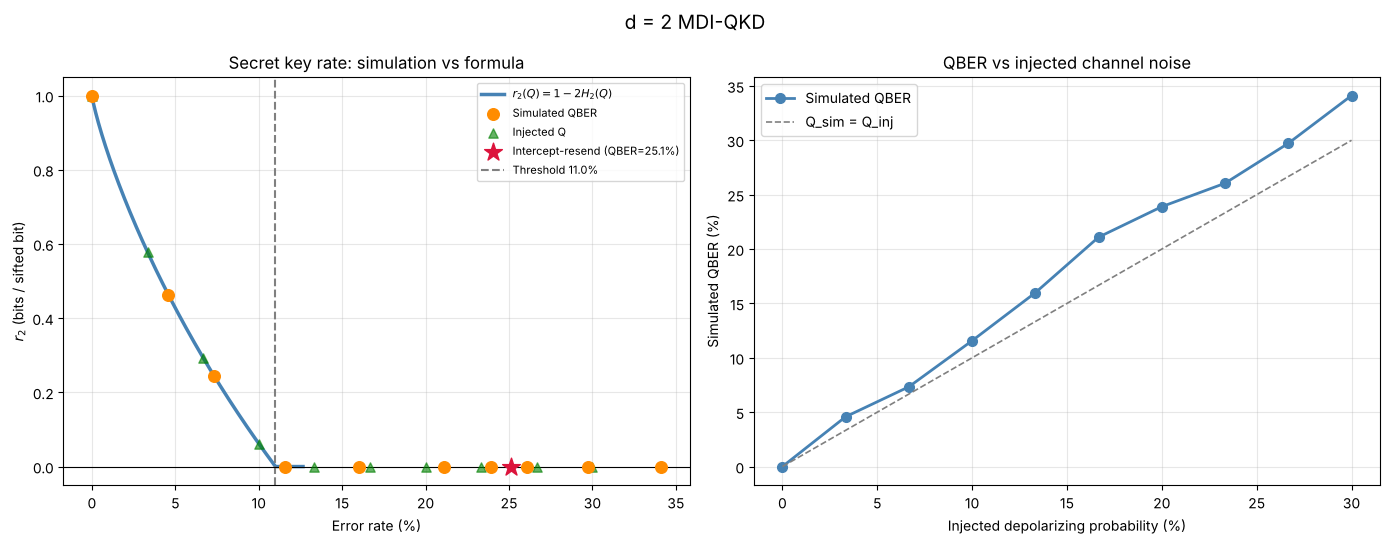

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
Q_curve = np.linspace(0.001, th_d2 * 1.15, 300)

ax = axes[0]
ax.plot(Q_curve * 100, [r2_formula(Q) for Q in Q_curve], lw=2.5, color="steelblue", label=r"$r_2(Q)=1-2H_2(Q)$")
ax.scatter(sweep_d2["Q_simulated"] * 100, sweep_d2["r_at_Q_sim"], s=70, color="darkorange", zorder=5, label="Simulated QBER")
ax.scatter(sweep_d2["Q_injected"] * 100, sweep_d2["r_at_Q_inj"], s=45, color="green", marker="^", alpha=0.6, zorder=4, label="Injected Q")
ax.scatter([qber_d2_e * 100], [r2_formula(qber_d2_e)], s=180, color="crimson", marker="*", zorder=6,
           label=f"Intercept-resend (QBER={qber_d2_e*100:.1f}%)")
ax.axvline(th_d2 * 100, color="gray", lw=1.5, ls="--", label=f"Threshold {th_d2*100:.1f}%")
ax.axhline(0, color="black", lw=0.8)
ax.set_xlabel("Error rate (%)"); ax.set_ylabel(r"$r_2$ (bits / sifted bit)")
ax.set_title("Secret key rate: simulation vs formula")
ax.legend(fontsize=8); ax.grid(alpha=0.3)

ax = axes[1]
ax.plot(sweep_d2["Q_injected"] * 100, sweep_d2["Q_simulated"] * 100, "o-", color="steelblue", lw=2, ms=7, label="Simulated QBER")
ax.plot([0, 30], [0, 30], color="gray", ls="--", lw=1.2, label="Q_sim = Q_inj")
ax.set_xlabel("Injected depolarizing probability (%)"); ax.set_ylabel("Simulated QBER (%)")
ax.set_title("QBER vs injected channel noise")
ax.legend(); ax.grid(alpha=0.3)
plt.suptitle("d = 2 MDI-QKD", fontsize=14)
plt.tight_layout()
plt.show()

### Sifted rounds, key alignment and error positions
The number of sifted rounds depends only on basis matching and $P_S$, not on the noise level.
Noise changes which outcome Charlie announces, not whether he gets one.

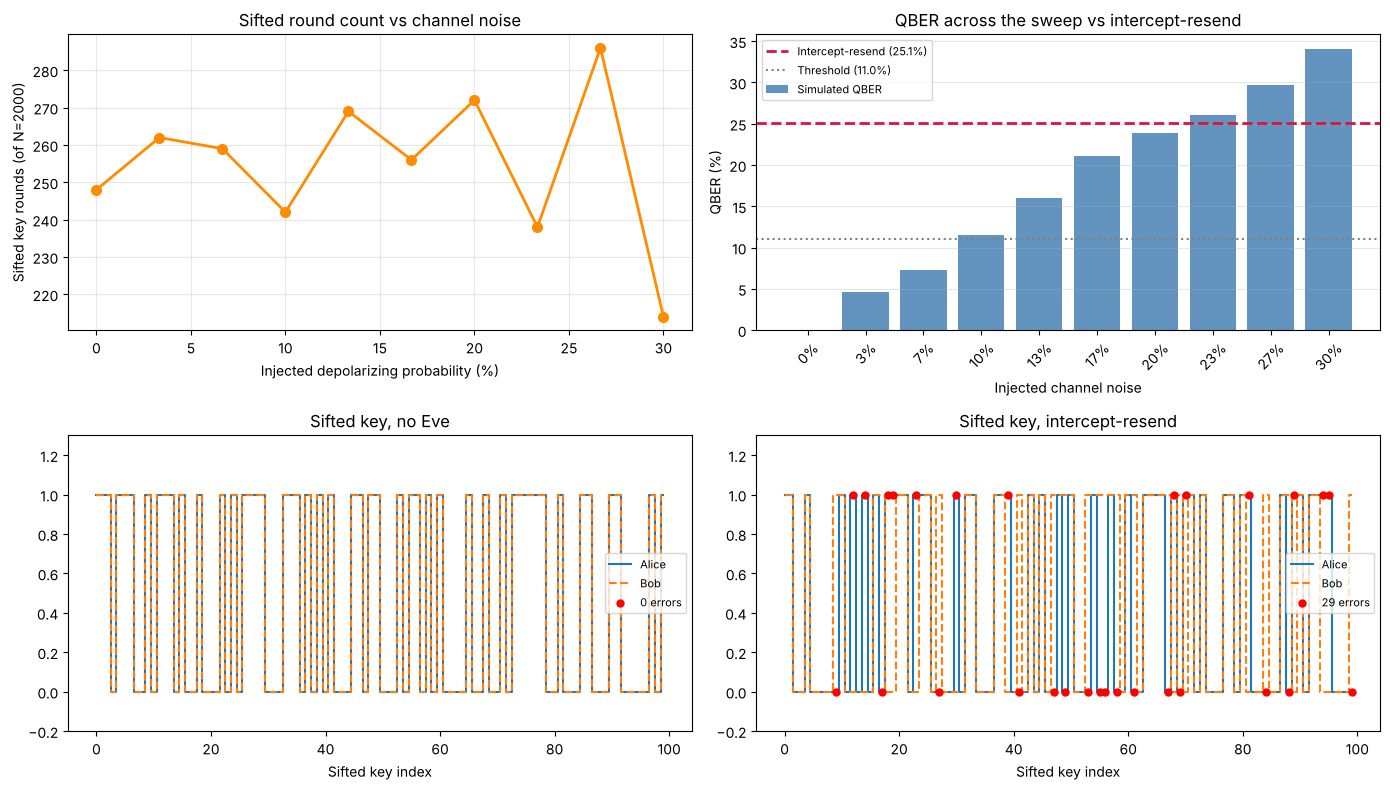

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

ax = axes[0, 0]
ax.plot(sweep_d2["Q_injected"] * 100, sweep_d2["sifted"], "o-", color="darkorange", lw=2, ms=7)
ax.set_xlabel("Injected depolarizing probability (%)"); ax.set_ylabel(f"Sifted key rounds (of N={N_D2})")
ax.set_title("Sifted round count vs channel noise"); ax.grid(alpha=0.3)

ax = axes[0, 1]
labels = [f"{q*100:.0f}%" for q in sweep_d2["Q_injected"]]
ax.bar(np.arange(len(sweep_d2)), sweep_d2["Q_simulated"] * 100, color="steelblue", alpha=0.85, label="Simulated QBER")
ax.axhline(qber_d2_e * 100, color="crimson", ls="--", lw=2, label=f"Intercept-resend ({qber_d2_e*100:.1f}%)")
ax.axhline(th_d2 * 100, color="gray", ls=":", lw=1.5, label=f"Threshold ({th_d2*100:.1f}%)")
ax.set_xticks(np.arange(len(sweep_d2))); ax.set_xticklabels(labels, rotation=45)
ax.set_xlabel("Injected channel noise"); ax.set_ylabel("QBER (%)")
ax.set_title("QBER across the sweep vs intercept-resend"); ax.legend(fontsize=8); ax.grid(alpha=0.3, axis="y")

for ax, alice, bob, title in [(axes[1, 0], alice_d2_no, bob_d2_no, "Sifted key, no Eve"),
                              (axes[1, 1], alice_d2_e,  bob_d2_e,  "Sifted key, intercept-resend")]:
    n = min(100, len(alice))
    a_arr, b_arr = np.array(alice[:n]), np.array(bob[:n])
    ax.step(np.arange(n), a_arr, where="mid", label="Alice")
    ax.step(np.arange(n), b_arr, where="mid", ls="--", label="Bob")
    err = np.where(a_arr != b_arr)[0]
    ax.scatter(err, a_arr[err], color="red", s=25, zorder=5, label=f"{len(err)} errors")
    ax.set_ylim(-0.2, 1.3); ax.set_title(title); ax.set_xlabel("Sifted key index"); ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 3. d = 3 (qutrit) MDI-QKD

Bases: ordinary $\{|0\rangle,|1\rangle,|2\rangle\}$ and bar (Fourier)
$|\bar j\rangle = \frac{1}{\sqrt3}\sum_k \omega^{jk}|k\rangle$, with $\omega = e^{2\pi i/3}$.

Bell states in the convention $|\Phi_{k,l}\rangle = \frac{1}{\sqrt3}\sum_{m}\omega^{ml}|m+k,\, m\rangle$. The
three $l=0$ states are resolvable ($P_S = 1/3$), and Bob corrects with $b_{\rm corr} = (b + k) \bmod 3$.

Each qutrit is padded into two qubits (4 levels, 3 used). Depolarizing noise acts on all four wires.

Key rate (Sheridan–Scarani): $r_3(Q) = \max\{0,\ \log_2 3\,(1-2Q) - 2H_2(Q)\}$.

MUB overlap |<i|bar j>|^2:
 [[0.3333 0.3333 0.3333]
 [0.3333 0.3333 0.3333]
 [0.3333 0.3333 0.3333]]
Bell basis orthonormal: True


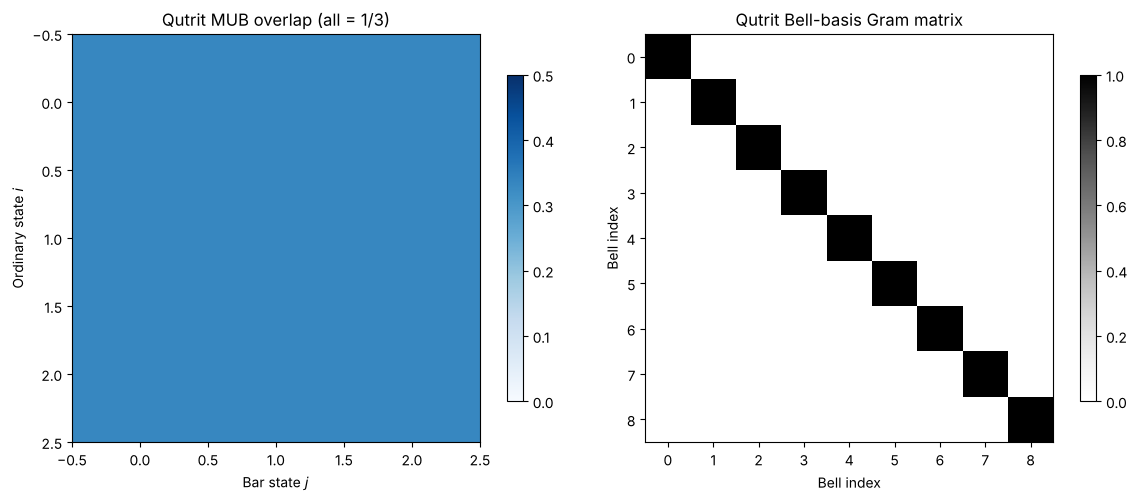

In [ ]:
DIM_D3      = 3
N_D3        = 5000   # rounds per run
N_NOISE_D3  = 10
np.random.seed(42)

omega3 = np.exp(2j * np.pi / 3)
ordinary_basis = np.eye(3, dtype=complex)                    # columns = |0>, |1>, |2>
bar_basis = np.array([[1, 1, 1],
                      [1, omega3, omega3**2],
                      [1, omega3**2, omega3]], dtype=complex) / np.sqrt(3)   # columns = |bar j>

overlap_d3 = np.abs(ordinary_basis.conj().T @ bar_basis) ** 2
print("MUB overlap |<i|bar j>|^2:\n", np.round(overlap_d3, 4))


def generate_qutrit_state():
    """Random basis and symbol; returns basis name, symbol and state vector."""
    basis_choice = np.random.randint(0, 2)
    symbol = np.random.randint(0, 3)
    if basis_choice == 0:
        return {"basis": "ordinary", "symbol": symbol, "state": ordinary_basis[:, symbol]}
    return {"basis": "bar", "symbol": symbol, "state": bar_basis[:, symbol]}


def bell_state_vec_d3(k, l):
    """|Phi_{k,l}> = (1/sqrt 3) sum_m w^{ml} |m+k, m>."""
    state = np.zeros(9, dtype=complex)
    for m in range(3):
        state[((m + k) % 3) * 3 + m] += omega3 ** (m * l)
    return state / np.sqrt(3)


bell_list_d3 = [(k, l, bell_state_vec_d3(k, l)) for k in range(3) for l in range(3)]
DIST_D3 = [0, 3, 6]   # (k, l=0) for k = 0, 1, 2

gram_d3 = np.array([[abs(np.vdot(v1, v2)) ** 2 for (_, _, v2) in bell_list_d3] for (_, _, v1) in bell_list_d3])
print("Bell basis orthonormal:", np.allclose(gram_d3, np.eye(9)))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
im = axes[0].imshow(overlap_d3, vmin=0, vmax=0.5, cmap="Blues")
axes[0].set_title("Qutrit MUB overlap (all = 1/3)")
axes[0].set_xlabel(r"Bar state $j$"); axes[0].set_ylabel("Ordinary state $i$")
fig.colorbar(im, ax=axes[0], shrink=0.8)
im = axes[1].imshow(gram_d3, cmap="Greys")
axes[1].set_title("Qutrit Bell-basis Gram matrix")
axes[1].set_xlabel("Bell index"); axes[1].set_ylabel("Bell index")
fig.colorbar(im, ax=axes[1], shrink=0.8)
plt.tight_layout()
plt.show()

### Channel circuit and BSM
1. Prepare $|\psi_A\rangle \otimes |\psi_B\rangle$ in a padded 4-qubit register.
2. Apply `DepolarizingChannel(p)` to every wire.
3. Project the logical $9\times9$ block onto the Bell basis: $p_i = \langle\Phi_i|\rho|\Phi_i\rangle$.
4. Population outside the logical block (trace $< 1$) counts as a lost round.

In [ ]:
N_QUBITS_D3 = 2
DIM_PAD_D3  = 2 ** N_QUBITS_D3
dev_d3 = qml.device("default.mixed", wires=2 * N_QUBITS_D3)


def pad_vec_d3(v3):
    vp = np.zeros(DIM_PAD_D3, dtype=complex)
    vp[:3] = v3
    return vp


@qml.qnode(dev_d3)
def channel_circuit_d3(vec_a, vec_b, p_dep=0.0):
    qml.StatePrep(np.kron(pad_vec_d3(vec_a), pad_vec_d3(vec_b)), wires=range(2 * N_QUBITS_D3))
    if p_dep > 0:
        for w in range(2 * N_QUBITS_D3):
            qml.DepolarizingChannel(p_dep, wires=w)
    return qml.density_matrix(wires=range(2 * N_QUBITS_D3))


def extract_logical_rho(rho_padded, d, n_qubits):
    """Logical d^2 x d^2 block of a padded two-qudit density matrix."""
    dim_pad = 2 ** n_qubits
    idx = np.array([a * dim_pad + b for a in range(d) for b in range(d)])
    return rho_padded[np.ix_(idx, idx)]


def charlie_bsm_d3(alice_state, bob_state, Q_noise=0.0):
    """Noisy qutrit BSM; returns (success, k)."""
    rho = np.array(channel_circuit_d3(alice_state, bob_state, p_dep=Q_noise))
    logical = extract_logical_rho(rho, 3, N_QUBITS_D3)
    trace = float(np.real(np.trace(logical)))
    if trace < 1e-9:
        return False, None
    logical = logical / trace
    probs = np.clip([float(np.real(np.vdot(bs, logical @ bs))) for (_, _, bs) in bell_list_d3], 0.0, None)

    # Success probability includes the population kept in the logical subspace
    p_success = sum(probs[i] for i in DIST_D3) * trace
    if np.random.random() > p_success:
        return False, None
    p_cond = np.array([probs[i] for i in DIST_D3])
    chosen = np.random.choice(DIST_D3, p=p_cond / p_cond.sum())
    return True, bell_list_d3[chosen][0]


a0 = ordinary_basis[:, 0]
succ, k_counts = 0, {0: 0, 1: 0, 2: 0}
for _ in range(3000):
    ok, k = charlie_bsm_d3(a0, a0)
    if ok:
        succ += 1
        k_counts[k] += 1
print(f"|0>|0>: success rate = {succ/3000:.3f} (1/3), k distribution = { {k: round(v/succ, 3) for k, v in k_counts.items()} }")

for Q in [0.0, 0.1, 0.3]:
    np.random.seed(0)
    errs = sift = 0
    for _ in range(1500):
        ok, k = charlie_bsm_d3(a0, a0, Q_noise=Q)
        if ok:
            sift += 1
            errs += int(k != 0)
    print(f"Q_noise={Q:.2f}: key-error rate = {errs/sift if sift else 0:.4f}  (sifted={sift})")

|0>|0>: success rate = 0.317 (1/3), k distribution = {0: 1.0, 1: 0.0, 2: 0.0}


Q_noise=0.00: key-error rate = 0.0000  (sifted=511)


Q_noise=0.10: key-error rate = 0.2235  (sifted=510)


Q_noise=0.30: key-error rate = 0.4841  (sifted=471)


### Protocol round, baseline and intercept-resend
Key rounds are ordinary-basis rounds in which both bases match and the BSM succeeds. Bar-basis
rounds would require $l \neq 0$ Bell states for a consistent correction, so they are not used for key.

Intercept-resend: Eve measures in a random basis. If it matches Alice's basis she resends the
correct symbol, and otherwise she resends a uniformly random symbol in her own basis.

In [ ]:
def eve_intercept_d3(alice_info):
    """Intercept-resend on a qutrit; returns Eve's basis index, symbol and resent state."""
    eve_basis_idx = np.random.randint(0, 2)
    alice_basis_idx = 0 if alice_info["basis"] == "ordinary" else 1
    eve_sym = alice_info["symbol"] if eve_basis_idx == alice_basis_idx else np.random.randint(0, 3)
    if eve_basis_idx == 0:
        return eve_basis_idx, eve_sym, ordinary_basis[:, eve_sym], "ordinary"
    return eve_basis_idx, eve_sym, bar_basis[:, eve_sym], "bar"


def protocol_round_d3(Q_noise=0.0, with_eve=False):
    """One qutrit MDI-QKD round."""
    alice = generate_qutrit_state()
    bob   = generate_qutrit_state()
    tx_state, eve_symbol, channel_Q = alice["state"].copy(), None, Q_noise
    if with_eve:
        _, eve_symbol, tx_state, _ = eve_intercept_d3(alice)
        channel_Q = 0.0
    success, k = charlie_bsm_d3(tx_state, bob["state"], Q_noise=channel_Q)
    basis_match = alice["basis"] == bob["basis"]
    return {"alice": alice, "bob": bob, "success": success, "basis_match": basis_match,
            "keep": success and basis_match, "bell_k": k,
            "bob_corrected": (bob["symbol"] + k) % 3 if success else None,
            "eve_symbol": eve_symbol}


def key_stats_d3(records):
    """QSER and keys from ordinary-basis sifted rounds."""
    a_key, b_key, e_key, errs = [], [], [], 0
    for r in records:
        if r["keep"] and r["alice"]["basis"] == "ordinary":
            a_key.append(r["alice"]["symbol"])
            b_key.append(r["bob_corrected"])
            e_key.append(r["eve_symbol"])
            errs += int(r["bob_corrected"] != r["alice"]["symbol"])
    q = errs / len(a_key) if a_key else 0.0
    return q, a_key, b_key, e_key


def r3_formula(Q):
    """Sheridan-Scarani qutrit key rate."""
    return max(0.0, np.log2(3) * (1 - 2 * Q) - 2 * H2(Q))


records_d3 = [protocol_round_d3() for _ in range(N_D3)]
print(f"Basis match rate:  {sum(r['basis_match'] for r in records_d3)/N_D3:.3f}  (0.5)")
print(f"BSM success rate:  {sum(r['success'] for r in records_d3)/N_D3:.3f}  (1/3)")
print(f"Sifted round rate: {sum(r['keep'] for r in records_d3)/N_D3:.3f}  (1/6)")

qser_d3_no, _, _, _ = key_stats_d3(records_d3)
assert qser_d3_no == 0.0
print(f"\nKey QSER (no noise) = {qser_d3_no:.4f}   r3 = {r3_formula(qser_d3_no):.4f} (max log2 3 = {np.log2(3):.4f})")

records_d3_eve = [protocol_round_d3(with_eve=True) for _ in range(N_D3)]
qser_d3_e, alice_d3_e, bob_d3_e, eve_d3_e = key_stats_d3(records_d3_eve)
valid_t = [(a, e) for a, e in zip(alice_d3_e, eve_d3_e) if e is not None]
eve_success_d3 = sum(a == e for a, e in valid_t) / len(valid_t) if valid_t else 0.0
print(f"Key QSER (intercept-resend) = {qser_d3_e:.4f}  (theory {0.5*2/3:.4f})")
print(f"Eve's correct-guess rate    = {eve_success_d3:.3f}")

Basis match rate:  0.496  (0.5)
BSM success rate:  0.337  (1/3)
Sifted round rate: 0.166  (1/6)

Key QSER (no noise) = 0.0000   r3 = 1.5850 (max log2 3 = 1.5850)


Key QSER (intercept-resend) = 0.3470  (theory 0.3333)
Eve's correct-guess rate    = 0.655


### Noise sweep and validation against $r_3(Q)$

In [ ]:
th_d3_ss = brentq(lambda e: np.log2(3) * (1 - 2 * e) - 2 * H2(e), 1e-6, 0.499)

noise_levels_d3 = np.linspace(0.0, 0.30, N_NOISE_D3)
rows = []
for i, Q_inj in enumerate(noise_levels_d3):
    np.random.seed(300 + i)
    recs = [protocol_round_d3(Q_noise=float(Q_inj)) for _ in range(N_D3)]
    q_sim, a_key, b_key, _ = key_stats_d3(recs)
    rows.append({"Q_injected": float(Q_inj), "Q_simulated": q_sim,
                 "r_at_Q_sim": r3_formula(q_sim), "r_at_Q_inj": r3_formula(float(Q_inj)),
                 "sifted": len(a_key)})
    print(f"  Q_inj={Q_inj:.3f}  Q_sim={q_sim:.4f}  sifted={len(a_key)}  r3(Q_sim)={r3_formula(q_sim):.4f}")
sweep_d3 = pd.DataFrame(rows)
print(f"\nQutrit zero-rate threshold (Sheridan-Scarani): {th_d3_ss*100:.2f}%")

  Q_inj=0.000  Q_sim=0.0000  sifted=430  r3(Q_sim)=1.5850


  Q_inj=0.033  Q_sim=0.0706  sifted=425  r3(Q_sim)=0.6250


  Q_inj=0.067  Q_sim=0.1024  sifted=420  r3(Q_sim)=0.3074


  Q_inj=0.100  Q_sim=0.1667  sifted=390  r3(Q_sim)=0.0000


  Q_inj=0.133  Q_sim=0.2207  sifted=376  r3(Q_sim)=0.0000


  Q_inj=0.167  Q_sim=0.2680  sifted=347  r3(Q_sim)=0.0000


  Q_inj=0.200  Q_sim=0.3023  sifted=344  r3(Q_sim)=0.0000


  Q_inj=0.233  Q_sim=0.3779  sifted=307  r3(Q_sim)=0.0000


  Q_inj=0.267  Q_sim=0.4232  sifted=345  r3(Q_sim)=0.0000


  Q_inj=0.300  Q_sim=0.4317  sifted=315  r3(Q_sim)=0.0000

Qutrit zero-rate threshold (Sheridan-Scarani): 13.68%


Validation figure: key rate per sifted trit against injected depolarizing noise per physical qubit.
The solid line evaluates $r_3$ at the simulated QSER and the dashed line at the injected level.
Because all four physical qubits are depolarized, the simulated QSER sits above the injected level.

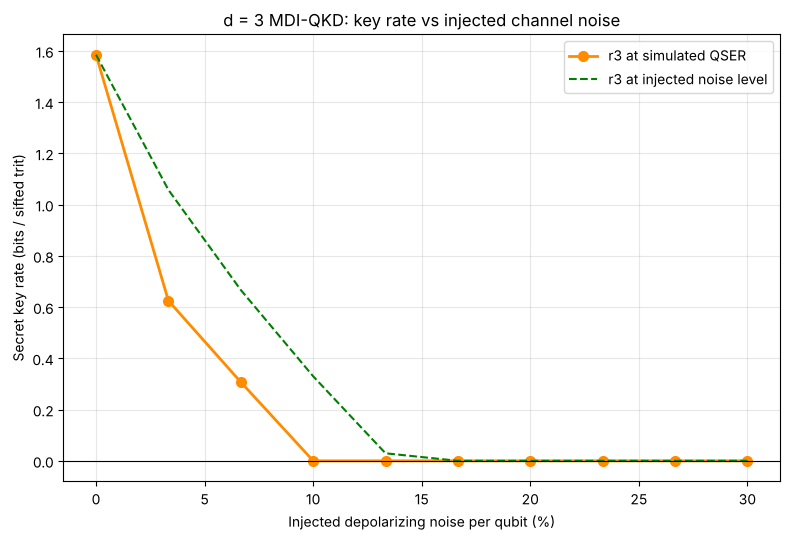

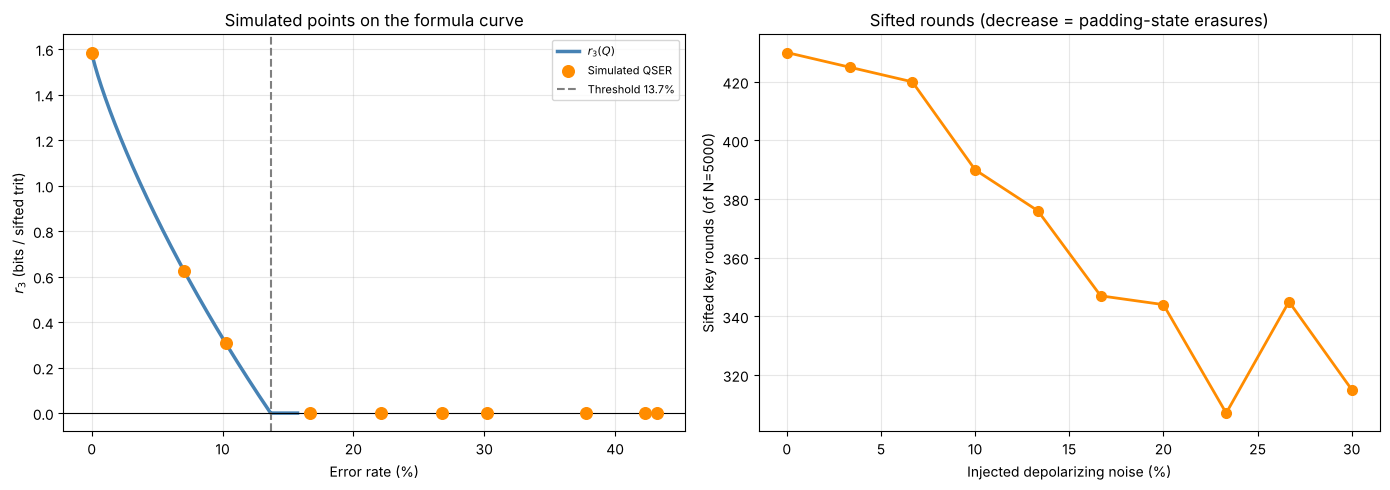

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.plot(sweep_d3["Q_injected"] * 100, sweep_d3["r_at_Q_sim"], "o-", color="darkorange", lw=2, ms=7, label="r3 at simulated QSER")
ax.plot(sweep_d3["Q_injected"] * 100, sweep_d3["r_at_Q_inj"], "--", color="green", lw=1.5, label="r3 at injected noise level")
ax.axhline(0, color="black", lw=0.8)
ax.set_xlabel("Injected depolarizing noise per qubit (%)")
ax.set_ylabel("Secret key rate (bits / sifted trit)")
ax.set_title("d = 3 MDI-QKD: key rate vs injected channel noise")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ax = axes[0]
Q_curve = np.linspace(0.001, th_d3_ss * 1.15, 300)
ax.plot(Q_curve * 100, [r3_formula(Q) for Q in Q_curve], lw=2.5, color="steelblue", label=r"$r_3(Q)$")
ax.scatter(sweep_d3["Q_simulated"] * 100, sweep_d3["r_at_Q_sim"], s=70, color="darkorange", zorder=5, label="Simulated QSER")
ax.axvline(th_d3_ss * 100, color="gray", ls="--", label=f"Threshold {th_d3_ss*100:.1f}%")
ax.axhline(0, color="black", lw=0.8)
ax.set_xlabel("Error rate (%)"); ax.set_ylabel(r"$r_3$ (bits / sifted trit)")
ax.set_title("Simulated points on the formula curve"); ax.legend(fontsize=8); ax.grid(alpha=0.3)

ax = axes[1]
ax.plot(sweep_d3["Q_injected"] * 100, sweep_d3["sifted"], "o-", color="darkorange", lw=2, ms=7)
ax.set_xlabel("Injected depolarizing noise (%)"); ax.set_ylabel(f"Sifted key rounds (of N={N_D3})")
ax.set_title("Sifted rounds (decrease = padding-state erasures)"); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Qubit vs qutrit summary

                 Metric  Qubit  Qutrit
          QSER (no Eve)  0.000   0.000
QSER (intercept-resend)  0.251   0.347
 Eve correct-guess rate  0.757   0.655
        Bits per symbol  1.000   1.585
            Bell states  4.000   9.000
Zero-rate threshold (%) 11.000  13.680


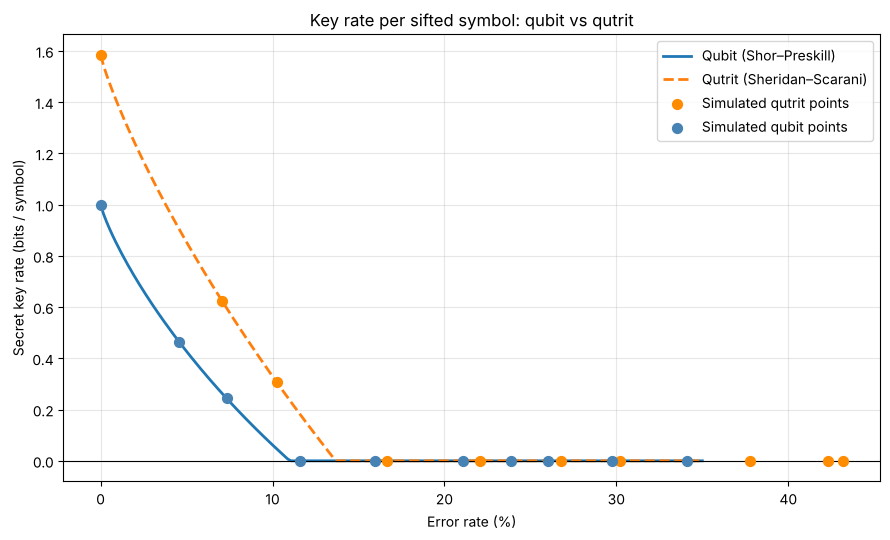

In [ ]:
e_vals = np.linspace(0, 0.35, 200)
comparison = pd.DataFrame({
    "Metric": ["QSER (no Eve)", "QSER (intercept-resend)", "Eve correct-guess rate",
               "Bits per symbol", "Bell states", "Zero-rate threshold (%)"],
    "Qubit":  [round(qber_d2_no, 4), round(qber_d2_e, 4), round(eve_success_d2, 3), 1, 4, round(th_d2 * 100, 2)],
    "Qutrit": [round(qser_d3_no, 4), round(qser_d3_e, 4), round(eve_success_d3, 3),
               round(float(np.log2(3)), 4), 9, round(th_d3_ss * 100, 2)],
})
print(comparison.to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.plot(e_vals * 100, [r2_formula(e) for e in e_vals], lw=2, label="Qubit (Shor–Preskill)")
ax.plot(e_vals * 100, [r3_formula(e) for e in e_vals], lw=2, ls="--", label="Qutrit (Sheridan–Scarani)")
ax.scatter(sweep_d3["Q_simulated"] * 100, sweep_d3["r_at_Q_sim"], color="darkorange", s=50, zorder=5, label="Simulated qutrit points")
ax.scatter(sweep_d2["Q_simulated"] * 100, sweep_d2["r_at_Q_sim"], color="steelblue", s=50, zorder=5, label="Simulated qubit points")
ax.axhline(0, color="black", lw=0.8)
ax.set_xlabel("Error rate (%)"); ax.set_ylabel("Secret key rate (bits / symbol)")
ax.set_title("Key rate per sifted symbol: qubit vs qutrit")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 4. d = 4 (ququart) MDI-QKD

Encoding $|k\rangle \to |k/\!/2,\ k \bmod 2\rangle$ on two qubits. Wires: Alice (0 high, 1 low), Bob (2 high, 3 low).

Fourier state $|\varphi_j\rangle = \tfrac12\sum_k i^{jk}|k\rangle$ factorises as
$(H|0\rangle\cdot Z^{j})_{\rm hi} \otimes (H|0\rangle\cdot S^{j})_{\rm lo}$, so it is prepared with gates only.

The depolarizing channel acts on Alice's two wires.

In [ ]:
D4         = 4
N_D4       = 8000   # rounds per run
N_NOISE_D4 = 12
OMEGA4     = np.exp(2j * np.pi / D4)
np.random.seed(42)

dev_d4 = qml.device("default.mixed", wires=4)
comp4  = np.eye(D4, dtype=complex)
had4   = np.array([[OMEGA4 ** (j * k) for k in range(D4)] for j in range(D4)], dtype=complex) / 2.0
assert np.allclose(np.abs(had4 @ comp4) ** 2, 0.25)

bell_list_d4 = build_bell_list(D4)
DIST_D4 = [i for i, (l, m, _) in enumerate(bell_list_d4) if l == 0]
gram_d4 = np.array([[abs(np.vdot(v1, v2)) ** 2 for (_, _, v2) in bell_list_d4] for (_, _, v1) in bell_list_d4])
assert np.allclose(gram_d4, np.eye(16))
print(f"MUB and Bell-basis checks passed. Resolvable Bell indices (l=0): {DIST_D4}")


def encode_comp(k, wire_hi, wire_lo):
    """Computational ququart |k> = |k//2, k%2>."""
    if k // 2 == 1:
        qml.PauliX(wires=wire_hi)
    if k % 2 == 1:
        qml.PauliX(wires=wire_lo)


def encode_had(j, wire_hi, wire_lo):
    """Fourier ququart |phi_j> via H on both wires, Z^j on high, S^j on low."""
    qml.Hadamard(wires=wire_hi)
    qml.Hadamard(wires=wire_lo)
    if j % 2 == 1:
        qml.PauliZ(wires=wire_hi)
    if j == 1:
        qml.S(wires=wire_lo)
    elif j == 2:
        qml.PauliZ(wires=wire_lo)
    elif j == 3:
        qml.adjoint(qml.S)(wires=wire_lo)


dev_check = qml.device("default.qubit", wires=2)


@qml.qnode(dev_check)
def had_state_check(j):
    encode_had(j, 0, 1)
    return qml.state()


for j in range(D4):
    expected = np.array([had4[j, k] for k in range(D4)])
    print(f"  |phi_{j}> gate encoding matches: {np.allclose(np.array(had_state_check(j)), expected)}")


@qml.qnode(dev_d4)
def charlie_circuit_d4(basis_a, sym_a, basis_b, sym_b, p_dep=0.0):
    """Joint density matrix for (basis, symbol) inputs; 0 = computational, 1 = Fourier."""
    (encode_comp if basis_a == 0 else encode_had)(sym_a, 0, 1)
    (encode_comp if basis_b == 0 else encode_had)(sym_b, 2, 3)
    if p_dep > 0:
        qml.DepolarizingChannel(p_dep, wires=0)
        qml.DepolarizingChannel(p_dep, wires=1)
    return qml.density_matrix(wires=range(4))


def bsm_from_rho_d4(rho_16):
    """Born-rule BSM on the 16x16 joint state; returns (success, m)."""
    probs = np.clip([float(np.real(np.vdot(bs, rho_16 @ bs))) for (_, _, bs) in bell_list_d4], 0.0, None)
    p_success = sum(probs[i] for i in DIST_D4)
    if np.random.random() > p_success:
        return False, None
    p_cond = np.array([probs[i] for i in DIST_D4])
    chosen = DIST_D4[np.random.choice(len(DIST_D4), p=p_cond / p_cond.sum())]
    return True, bell_list_d4[chosen][1]


np.random.seed(42)
succ, m_counts = 0, {m: 0 for m in range(D4)}
for _ in range(3000):
    ok, m = bsm_from_rho_d4(np.array(charlie_circuit_d4(0, 0, 0, 0)))
    if ok:
        succ += 1
        m_counts[m] += 1
print(f"BSM on |0>|0>: P_S = {succ/3000:.3f} (0.25), m distribution = { {k: round(v/succ, 2) for k, v in m_counts.items()} }")

MUB and Bell-basis checks passed. Resolvable Bell indices (l=0): [0, 4, 8, 12]
  |phi_0> gate encoding matches: True
  |phi_1> gate encoding matches: True
  |phi_2> gate encoding matches: True
  |phi_3> gate encoding matches: True


BSM on |0>|0>: P_S = 0.258 (0.25), m distribution = {0: 1.0, 1: 0.0, 2: 0.0, 3: 0.0}


### Protocol engine, noise sweep and intercept-resend

In [ ]:
def run_protocol_d4(N, Q_noise=0.0, with_eve=False, seed=42):
    """Full ququart MDI-QKD run; returns QSER, sifted count and keys."""
    np.random.seed(seed)
    key_errors = key_sifted = 0
    alice_key, bob_key, eve_key = [], [], []

    for _ in range(N):
        basis_a = np.random.randint(0, 2)
        basis_b = np.random.randint(0, 2)
        sym_a   = np.random.randint(0, D4)
        sym_b   = np.random.randint(0, D4)

        tx_basis, tx_sym, eve_sym, p_dep = basis_a, sym_a, None, 0.0
        if with_eve:
            e_basis = np.random.randint(0, 2)
            e_sym   = sym_a if e_basis == basis_a else np.random.randint(0, D4)
            tx_basis, tx_sym, eve_sym = e_basis, e_sym, e_sym
        elif Q_noise > 0:
            p_dep = Q_noise

        rho = np.array(charlie_circuit_d4(tx_basis, tx_sym, basis_b, sym_b, p_dep=p_dep))
        ok, m = bsm_from_rho_d4(rho)
        if not ok or basis_a != basis_b or basis_a != 0:
            continue

        key_sifted += 1
        b_corr = (sym_b - m) % D4
        key_errors += int(b_corr != sym_a)
        alice_key.append(sym_a)
        bob_key.append(b_corr)
        if with_eve:
            eve_key.append(eve_sym)

    return {"Q_sim": key_errors / key_sifted if key_sifted else 0.0, "key_sifted": key_sifted,
            "alice_key": alice_key, "bob_key": bob_key, "eve_key": eve_key}


th_d4 = zero_rate_threshold(D4)
noise_levels_d4 = np.linspace(0.0, th_d4 * 0.98, N_NOISE_D4)
print(f"d=4 zero-rate threshold: {th_d4*100:.2f}%\n")

results_d4 = []
for i, Q_inj in enumerate(noise_levels_d4):
    r = run_protocol_d4(N_D4, Q_noise=Q_inj, seed=42 + i)
    results_d4.append({"Q_injected": Q_inj, "Q_simulated": r["Q_sim"],
                       "r_at_Q_sim": r_d_formula(r["Q_sim"], D4), "r_at_Q_inj": r_d_formula(Q_inj, D4),
                       "R_at_Q_sim": R_total_formula(r["Q_sim"], D4), "R_at_Q_inj": R_total_formula(Q_inj, D4),
                       "key_sifted": r["key_sifted"], "alice_key": r["alice_key"], "bob_key": r["bob_key"]})
    print(f"  Q_inj={Q_inj*100:5.2f}%  Q_sim={r['Q_sim']*100:5.2f}%  r(Q_sim)={r_d_formula(r['Q_sim'], D4):.4f}  n={r['key_sifted']}")
sweep_d4 = pd.DataFrame(results_d4)

r_eve_d4 = run_protocol_d4(N_D4, with_eve=True, seed=99)
qser_d4_e = r_eve_d4["Q_sim"]
valid_eve = [(a, e) for a, e in zip(r_eve_d4["alice_key"], r_eve_d4["eve_key"]) if e is not None]
print(f"\nIntercept-resend: QSER = {qser_d4_e:.4f}  (theory {0.5*(D4-1)/D4:.4f})")
print(f"Eve's correct-guess rate = {sum(a == e for a, e in valid_eve)/len(valid_eve):.3f}  (random 1/d = 0.25)")

d=4 zero-rate threshold: 18.93%



  Q_inj= 0.00%  Q_sim= 0.00%  r(Q_sim)=2.0000  n=524


  Q_inj= 1.69%  Q_sim= 2.85%  r(Q_sim)=1.5366  n=492


  Q_inj= 3.37%  Q_sim= 4.24%  r(Q_sim)=1.3595  n=472


  Q_inj= 5.06%  Q_sim= 7.99%  r(Q_sim)=0.9429  n=463


  Q_inj= 6.75%  Q_sim= 8.21%  r(Q_sim)=0.9203  n=487


... (4 outputs left out)

  Q_inj=15.18%  Q_sim=17.76%  r(Q_sim)=0.0877  n=535


  Q_inj=16.86%  Q_sim=19.68%  r(Q_sim)=0.0000  n=503


  Q_inj=18.55%  Q_sim=20.83%  r(Q_sim)=0.0000  n=509



Intercept-resend: QSER = 0.4012  (theory 0.3750)
Eve's correct-guess rate = 0.615  (random 1/d = 0.25)


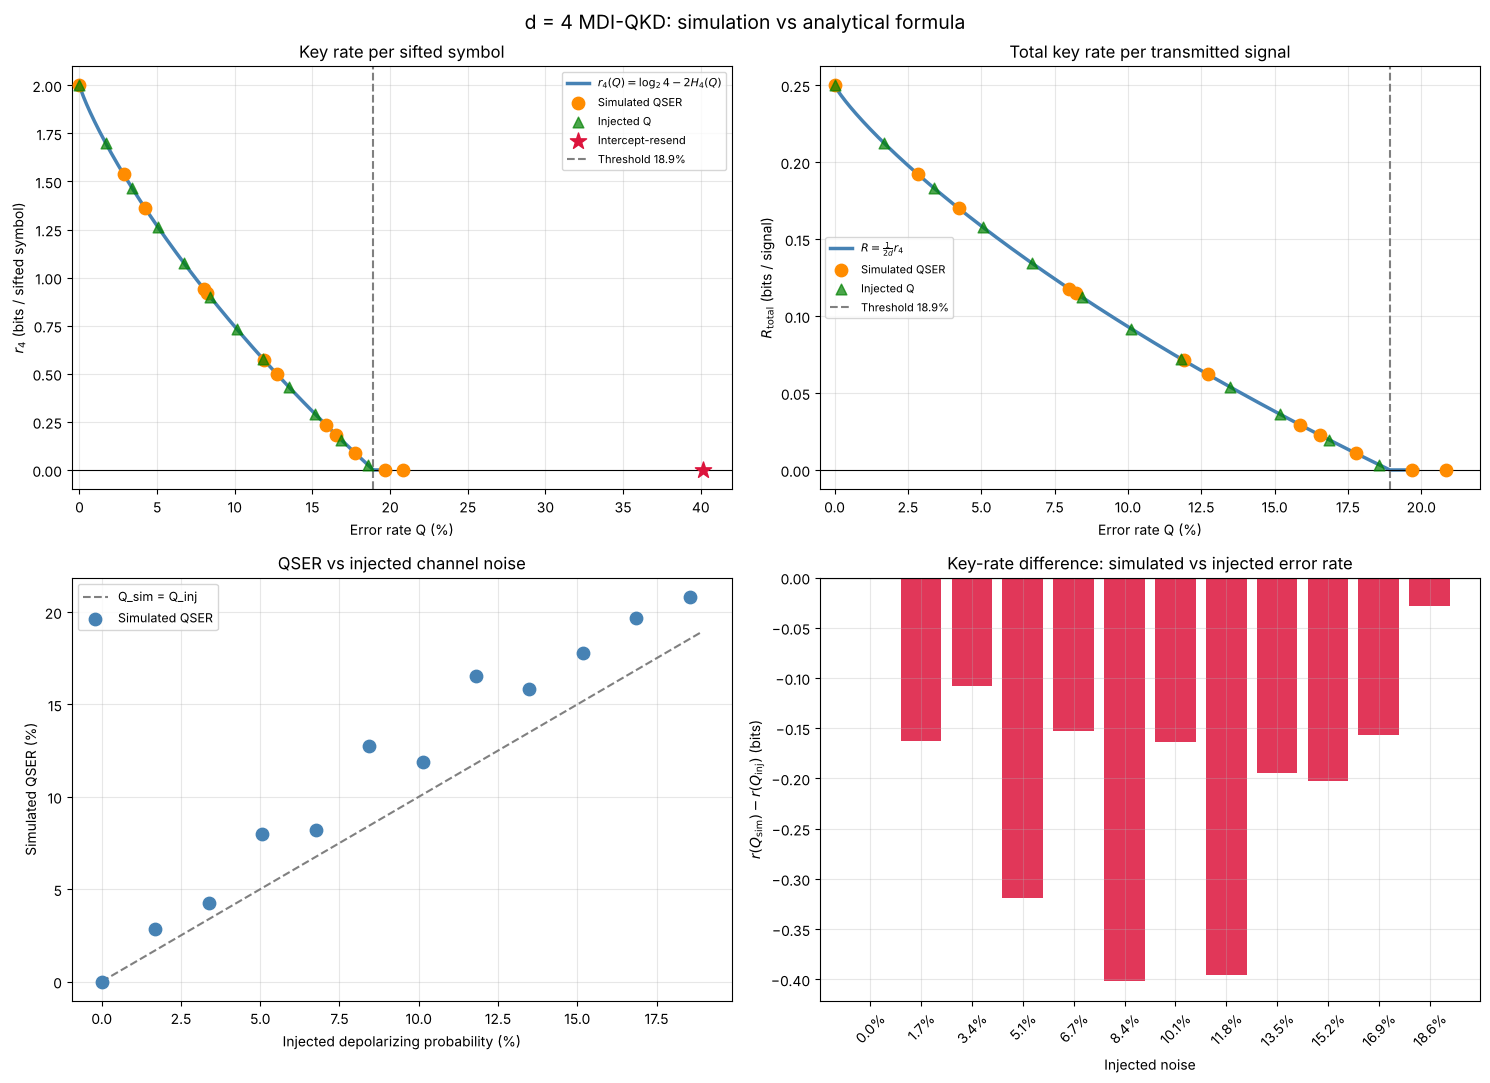

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11))
Q_curve = np.linspace(0.001, th_d4 * 1.05, 500)
q_sim, q_inj = sweep_d4["Q_simulated"].values, sweep_d4["Q_injected"].values

ax = axes[0, 0]
ax.plot(Q_curve * 100, [r_d_formula(Q, D4) for Q in Q_curve], lw=2.5, color="steelblue", label=r"$r_4(Q)=\log_2 4-2H_4(Q)$")
ax.scatter(q_sim * 100, sweep_d4["r_at_Q_sim"], s=80, color="darkorange", zorder=5, label="Simulated QSER")
ax.scatter(q_inj * 100, sweep_d4["r_at_Q_inj"], s=60, color="green", marker="^", alpha=0.7, zorder=5, label="Injected Q")
ax.scatter([qser_d4_e * 100], [r_d_formula(qser_d4_e, D4)], s=150, color="crimson", marker="*", zorder=6, label="Intercept-resend")
ax.axvline(th_d4 * 100, color="gray", ls="--", label=f"Threshold {th_d4*100:.1f}%")
ax.axhline(0, color="black", lw=0.8)
ax.set_xlabel("Error rate Q (%)"); ax.set_ylabel(r"$r_4$ (bits / sifted symbol)")
ax.set_title("Key rate per sifted symbol"); ax.legend(fontsize=8); ax.grid(alpha=0.3); ax.set_xlim(-0.5, 42)

ax = axes[0, 1]
ax.plot(Q_curve * 100, [R_total_formula(Q, D4) for Q in Q_curve], lw=2.5, color="steelblue", label=r"$R=\frac{1}{2d}r_4$")
ax.scatter(q_sim * 100, sweep_d4["R_at_Q_sim"], s=80, color="darkorange", zorder=5, label="Simulated QSER")
ax.scatter(q_inj * 100, sweep_d4["R_at_Q_inj"], s=60, color="green", marker="^", alpha=0.7, zorder=5, label="Injected Q")
ax.axvline(th_d4 * 100, color="gray", ls="--", label=f"Threshold {th_d4*100:.1f}%")
ax.axhline(0, color="black", lw=0.8)
ax.set_xlabel("Error rate Q (%)"); ax.set_ylabel(r"$R_{\rm total}$ (bits / signal)")
ax.set_title("Total key rate per transmitted signal"); ax.legend(fontsize=8); ax.grid(alpha=0.3); ax.set_xlim(-0.5, 22)

ax = axes[1, 0]
ax.plot([0, th_d4 * 100], [0, th_d4 * 100], color="gray", ls="--", label="Q_sim = Q_inj")
ax.scatter(q_inj * 100, q_sim * 100, s=80, color="steelblue", zorder=5, label="Simulated QSER")
ax.set_xlabel("Injected depolarizing probability (%)"); ax.set_ylabel("Simulated QSER (%)")
ax.set_title("QSER vs injected channel noise"); ax.legend(fontsize=9); ax.grid(alpha=0.3)

ax = axes[1, 1]
delta_r = sweep_d4["r_at_Q_sim"].values - sweep_d4["r_at_Q_inj"].values
ax.bar(range(len(delta_r)), delta_r, color=["steelblue" if x >= 0 else "crimson" for x in delta_r], alpha=0.85)
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(range(len(delta_r))); ax.set_xticklabels([f"{q*100:.1f}%" for q in q_inj], rotation=45)
ax.set_xlabel("Injected noise"); ax.set_ylabel(r"$r(Q_{\rm sim}) - r(Q_{\rm inj})$ (bits)")
ax.set_title("Key-rate difference: simulated vs injected error rate"); ax.grid(alpha=0.3)
plt.suptitle("d = 4 MDI-QKD: simulation vs analytical formula", fontsize=14)
plt.tight_layout()
plt.show()

### Key alignment and per-symbol error distribution

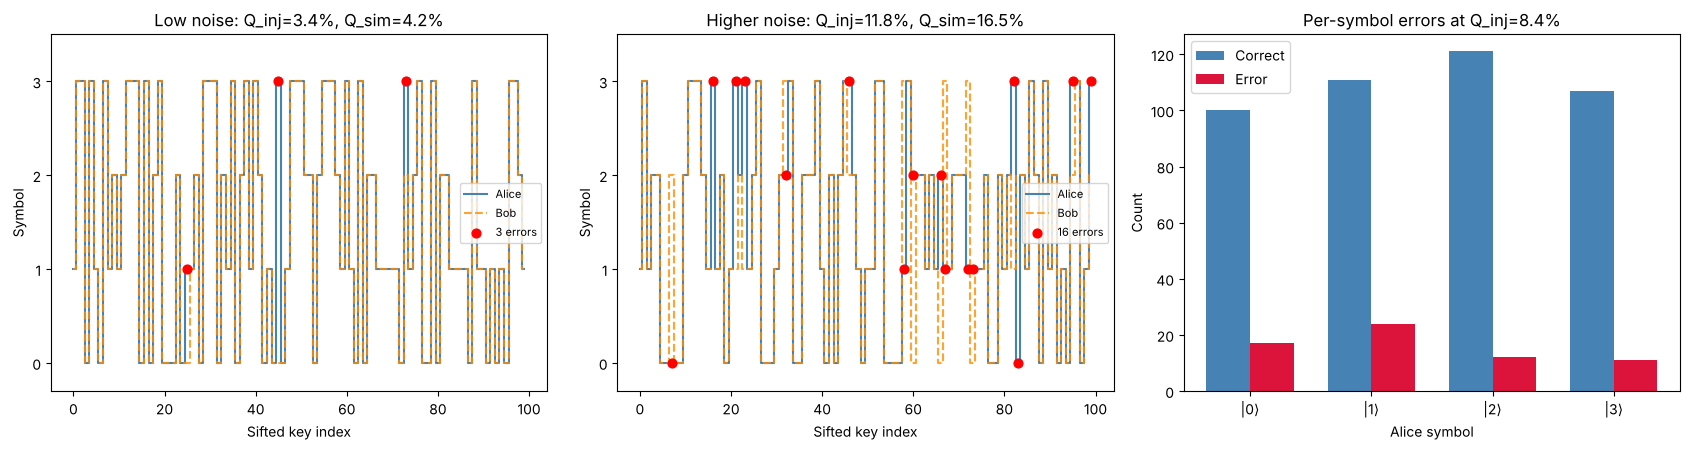

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for ax, idx, label in [(axes[0], 2, "Low noise"), (axes[1], 7, "Higher noise")]:
    row = results_d4[idx]
    ak, bk = np.array(row["alice_key"][:100]), np.array(row["bob_key"][:100])
    err = np.where(ak != bk)[0]
    ax.step(np.arange(len(ak)), ak, where="mid", lw=1.5, color="steelblue", label="Alice")
    ax.step(np.arange(len(bk)), bk, where="mid", lw=1.5, color="darkorange", ls="--", alpha=0.8, label="Bob")
    ax.scatter(err, ak[err], color="red", s=40, zorder=5, label=f"{len(err)} errors")
    ax.set_ylim(-0.3, 3.5); ax.set_yticks(range(4))
    ax.set_title(f"{label}: Q_inj={row['Q_injected']*100:.1f}%, Q_sim={row['Q_simulated']*100:.1f}%")
    ax.set_xlabel("Sifted key index"); ax.set_ylabel("Symbol"); ax.legend(fontsize=8)

ax = axes[2]
row = results_d4[5]
ak, bk = np.array(row["alice_key"]), np.array(row["bob_key"])
ax.bar(np.arange(D4) - 0.18, [np.sum((ak == bk) & (ak == s)) for s in range(D4)], 0.36, label="Correct", color="steelblue")
ax.bar(np.arange(D4) + 0.18, [np.sum((ak != bk) & (ak == s)) for s in range(D4)], 0.36, label="Error", color="crimson")
ax.set_xticks(range(D4)); ax.set_xticklabels([f"|{k}⟩" for k in range(D4)])
ax.set_xlabel("Alice symbol"); ax.set_ylabel("Count")
ax.set_title(f"Per-symbol errors at Q_inj={row['Q_injected']*100:.1f}%"); ax.legend()
plt.tight_layout()
plt.show()

## 5. d = 5, 6, 7 MDI-QKD (padded qudits)

Each qudit uses $n = \lceil\log_2 d\rceil = 3$ qubits (8 basis states, $d$ used). States are prepared with
`qml.StatePrep`. The logical $d^2$-dimensional block is extracted before Bell projection.

Two noise models are run:
- **Idealised symmetric $d$-ary channel:** Alice's symbol is replaced by a uniformly random
  different symbol with probability $Q_{\rm noise}$, followed by a noiseless statevector circuit.
  This is used as a reference and for convergence checks.
- **Physical channel noise:** `DepolarizingChannel` on every qubit of both registers
  (`default.mixed`). Padding-state population is counted as an erasure.

In [ ]:
DIMENSIONS = [5, 6, 7]
N_QUDIT       = 6000   # rounds per noise level (idealised channel)
N_NOISE_QUDIT = 10
np.random.seed(42)


def setup_dimension(d):
    """Number of qubits per qudit and the root of unity for dimension d."""
    return int(np.ceil(np.log2(d))), np.exp(2j * np.pi / d)


def padded_state(symbol, d, n_qubits, basis="comp"):
    """2^n statevector of |k> (comp) or |phi_j> (had), zero on padding states."""
    w = np.exp(2j * np.pi / d)
    vec = np.zeros(2 ** n_qubits, dtype=complex)
    if basis == "comp":
        vec[symbol] = 1.0
    else:
        for k in range(d):
            vec[k] = w ** (symbol * k) / np.sqrt(d)
    return vec


def extract_logical_vec(sv_padded, d, n_qubits):
    """Logical d^2 amplitudes from the padded two-qudit statevector."""
    dim_pad = 2 ** n_qubits
    return np.array([sv_padded[a * dim_pad + b] for a in range(d) for b in range(d)])


bell_data = {}
for d in DIMENSIONS:
    nq, _ = setup_dimension(d)
    comp = [padded_state(k, d, nq, "comp") for k in range(d)]
    had  = [padded_state(j, d, nq, "had") for j in range(d)]
    mub_ok = all(abs(abs(np.vdot(comp[k], had[j])) ** 2 - 1 / d) < 1e-10 for k in range(d) for j in range(d))
    bl = build_bell_list(d)
    gram = np.array([[np.vdot(v1, v2) for (_, _, v2) in bl] for (_, _, v1) in bl])
    dist = [i for i, (l, m, _) in enumerate(bl) if l == 0]
    bell_data[d] = {"bell_list": bl, "DIST": dist}
    print(f"d={d}: {nq} qubits/qudit ({2**nq - d} padding states), MUB ok={mub_ok}, "
          f"{len(bl)} Bell states, orthonormality error={np.max(np.abs(gram - np.eye(len(bl)))):.1e}, resolvable={len(dist)}")

d=5: 3 qubits/qudit (3 padding states), MUB ok=True, 25 Bell states, orthonormality error=4.4e-16, resolvable=5
d=6: 3 qubits/qudit (2 padding states), MUB ok=True, 36 Bell states, orthonormality error=1.1e-15, resolvable=6
d=7: 3 qubits/qudit (1 padding states), MUB ok=True, 49 Bell states, orthonormality error=1.8e-15, resolvable=7


### Padded register layout
The coloured block shows the logical $d\times d$ subspace of the two-qudit register. Grey cells are
padding combinations: they are unused at preparation, but depolarizing noise can populate them.

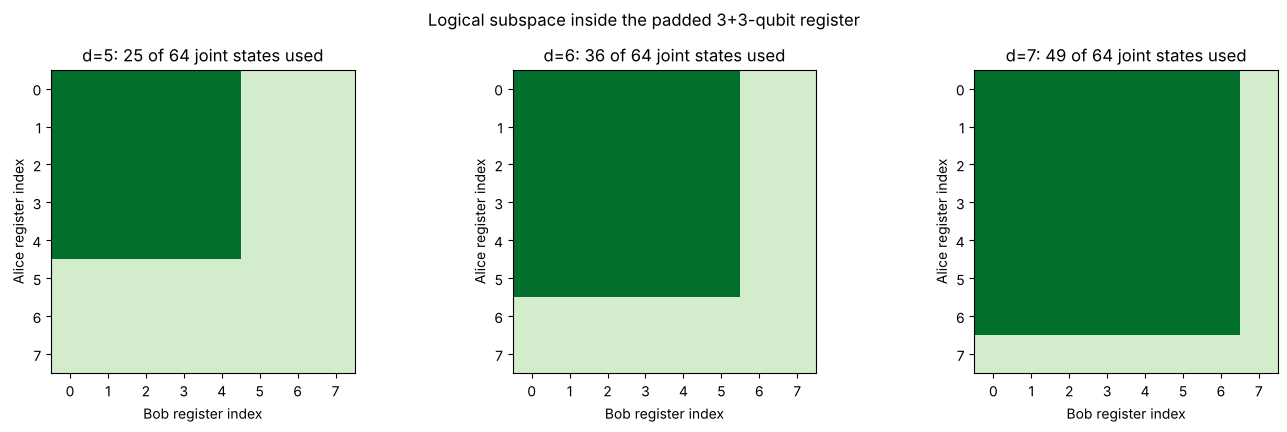

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.3))
for ax, d in zip(axes, DIMENSIONS):
    nq, _ = setup_dimension(d)
    dim_pad = 2 ** nq
    layout = np.zeros((dim_pad, dim_pad))
    layout[:d, :d] = 1
    ax.imshow(layout, cmap="Greens", vmin=-0.3, vmax=1.2)
    ax.set_title(f"d={d}: {d*d} of {dim_pad**2} joint states used")
    ax.set_xlabel("Bob register index"); ax.set_ylabel("Alice register index")
    ax.set_xticks(range(dim_pad)); ax.set_yticks(range(dim_pad))
plt.suptitle("Logical subspace inside the padded 3+3-qubit register")
plt.tight_layout()
plt.show()

### Statevector circuits and BSM check

In [ ]:
def bsm_vec(logical_vec, bell_list, dist_idx):
    """BSM on a pure logical joint state; returns (success, m)."""
    probs = np.array([abs(np.vdot(bs, logical_vec)) ** 2 for (_, _, bs) in bell_list])
    p_success = sum(probs[i] for i in dist_idx)
    if np.random.random() > p_success:
        return False, None
    p_cond = np.array([probs[i] for i in dist_idx])
    chosen = dist_idx[np.random.choice(len(dist_idx), p=p_cond / p_cond.sum())]
    return True, bell_list[chosen][1]


circuits = {}
for d in DIMENSIONS:
    nq, _ = setup_dimension(d)
    dev = qml.device("default.qubit", wires=2 * nq)

    def make_circuit(d=d, nq=nq, dev=dev):
        @qml.qnode(dev)
        def circuit(sym_a, basis_a, sym_b, basis_b):
            qml.StatePrep(padded_state(sym_a, d, nq, basis_a), wires=range(nq))
            qml.StatePrep(padded_state(sym_b, d, nq, basis_b), wires=range(nq, 2 * nq))
            return qml.state()
        return circuit

    circuits[d] = make_circuit()

for d in DIMENSIONS:
    nq, _ = setup_dimension(d)
    np.random.seed(0)
    succ, m0 = 0, 0
    for _ in range(1000):
        ok, m = bsm_vec(extract_logical_vec(np.array(circuits[d](0, "comp", 0, "comp")), d, nq),
                        bell_data[d]["bell_list"], bell_data[d]["DIST"])
        if ok:
            succ += 1
            m0 += int(m == 0)
    print(f"d={d}: P_S = {succ/1000:.3f} (expected {1/d:.3f}), P(m=0 | click) = {m0/succ:.3f}")

d=5: P_S = 0.210 (expected 0.200), P(m=0 | click) = 1.000


d=6: P_S = 0.187 (expected 0.167), P(m=0 | click) = 1.000


d=7: P_S = 0.162 (expected 0.143), P(m=0 | click) = 1.000


### Protocol engine: idealised symmetric d-ary channel

In [ ]:
def inject_symbol_noise(sym, Q_noise, d):
    """Replace sym by a uniformly random different symbol with probability Q_noise."""
    if np.random.random() < Q_noise:
        return np.random.choice([s for s in range(d) if s != sym])
    return sym


def run_protocol_qudit(d, N, Q_noise=0.0, with_eve=False, seed=42):
    """Qudit MDI-QKD with the idealised d-ary channel; returns QSER, sifted count and keys."""
    np.random.seed(seed)
    nq, _ = setup_dimension(d)
    bl, dist = bell_data[d]["bell_list"], bell_data[d]["DIST"]
    key_errors = key_sifted = 0
    alice_key, bob_key, eve_key = [], [], []

    for _ in range(N):
        basis_a = np.random.randint(0, 2)
        basis_b = np.random.randint(0, 2)
        sym_a   = np.random.randint(0, d)
        sym_b   = np.random.randint(0, d)

        tx_basis, tx_sym, eve_sym = basis_a, sym_a, None
        if with_eve:
            e_basis = np.random.randint(0, 2)
            e_sym   = sym_a if e_basis == basis_a else np.random.randint(0, d)
            tx_basis, tx_sym, eve_sym = e_basis, e_sym, e_sym
        elif Q_noise > 0:
            tx_sym = inject_symbol_noise(sym_a, Q_noise, d)

        sv = np.array(circuits[d](tx_sym, "comp" if tx_basis == 0 else "had",
                                  sym_b, "comp" if basis_b == 0 else "had"))
        ok, m = bsm_vec(extract_logical_vec(sv, d, nq), bl, dist)
        if not ok or basis_a != basis_b or basis_a != 0:
            continue

        key_sifted += 1
        b_corr = (sym_b - m) % d
        key_errors += int(b_corr != sym_a)
        alice_key.append(sym_a)
        bob_key.append(b_corr)
        if with_eve:
            eve_key.append(eve_sym)

    return {"Q_sim": key_errors / key_sifted if key_sifted else 0.0, "key_sifted": key_sifted,
            "alice_key": alice_key, "bob_key": bob_key, "eve_key": eve_key}


for d in DIMENSIONS:
    r0 = run_protocol_qudit(d, 2000, seed=1)
    assert r0["Q_sim"] == 0.0 and r0["alice_key"] == r0["bob_key"]
    print(f"d={d}: no-noise QSER = 0, keys match, sifted = {r0['key_sifted']}")

d=5: no-noise QSER = 0, keys match, sifted = 106


d=6: no-noise QSER = 0, keys match, sifted = 75


d=7: no-noise QSER = 0, keys match, sifted = 61


### Noise sweep (idealised channel) and intercept-resend

In [ ]:
thresholds = {d: zero_rate_threshold(d) for d in DIMENSIONS}
sweep_qudit = {}
t0 = time.time()
for d in DIMENSIONS:
    print(f"\nd={d}  (e* = {thresholds[d]*100:.2f}%)")
    rows = []
    for i, Q_inj in enumerate(np.linspace(0.0, thresholds[d] * 0.97, N_NOISE_QUDIT)):
        r = run_protocol_qudit(d, N_QUDIT, Q_noise=Q_inj, seed=100 + i)
        rows.append({"Q_injected": Q_inj, "Q_simulated": r["Q_sim"],
                     "r_at_Q_sim": r_d_formula(r["Q_sim"], d), "r_at_Q_inj": r_d_formula(Q_inj, d),
                     "R_at_Q_sim": R_total_formula(r["Q_sim"], d), "R_at_Q_inj": R_total_formula(Q_inj, d),
                     "key_sifted": r["key_sifted"]})
        print(f"  Q_inj={Q_inj*100:5.2f}%  Q_sim={r['Q_sim']*100:5.2f}%  r(Q_sim)={r_d_formula(r['Q_sim'], d):.4f}  n={r['key_sifted']}")
    sweep_qudit[d] = pd.DataFrame(rows)
print(f"\nSweep time: {time.time() - t0:.1f} s")

eve_results = {}
print(f"\n{'d':>3}  {'Q_sim':>8}  {'Q_theory':>9}  {'r(Q_sim)':>9}")
for d in DIMENSIONS:
    r = run_protocol_qudit(d, N_QUDIT, with_eve=True, seed=777)
    eve_results[d] = {"Q_sim": r["Q_sim"], "Q_theory": 0.5 * (d - 1) / d, "r_val": r_d_formula(r["Q_sim"], d)}
    print(f"{d:>3}  {r['Q_sim']:>8.4f}  {0.5*(d-1)/d:>9.4f}  {eve_results[d]['r_val']:>9.4f}")


d=5  (e* = 20.99%)


  Q_inj= 0.00%  Q_sim= 0.00%  r(Q_sim)=2.3219  n=300


  Q_inj= 2.26%  Q_sim= 2.81%  r(Q_sim)=1.8404  n=285


  Q_inj= 4.52%  Q_sim= 3.52%  r(Q_sim)=1.7413  n=284


  Q_inj= 6.79%  Q_sim= 6.06%  r(Q_sim)=1.4198  n=297


  Q_inj= 9.05%  Q_sim= 8.39%  r(Q_sim)=1.1551  n=310


... (24 outputs left out)

  Q_inj=23.01%  Q_sim=19.25%  r(Q_sim)=0.3989  n=213

Sweep time: 610.2 s

  d     Q_sim   Q_theory   r(Q_sim)


  5    0.4411     0.4000     0.0000


  6    0.4291     0.4167     0.0000


  7    0.4495     0.4286     0.0000


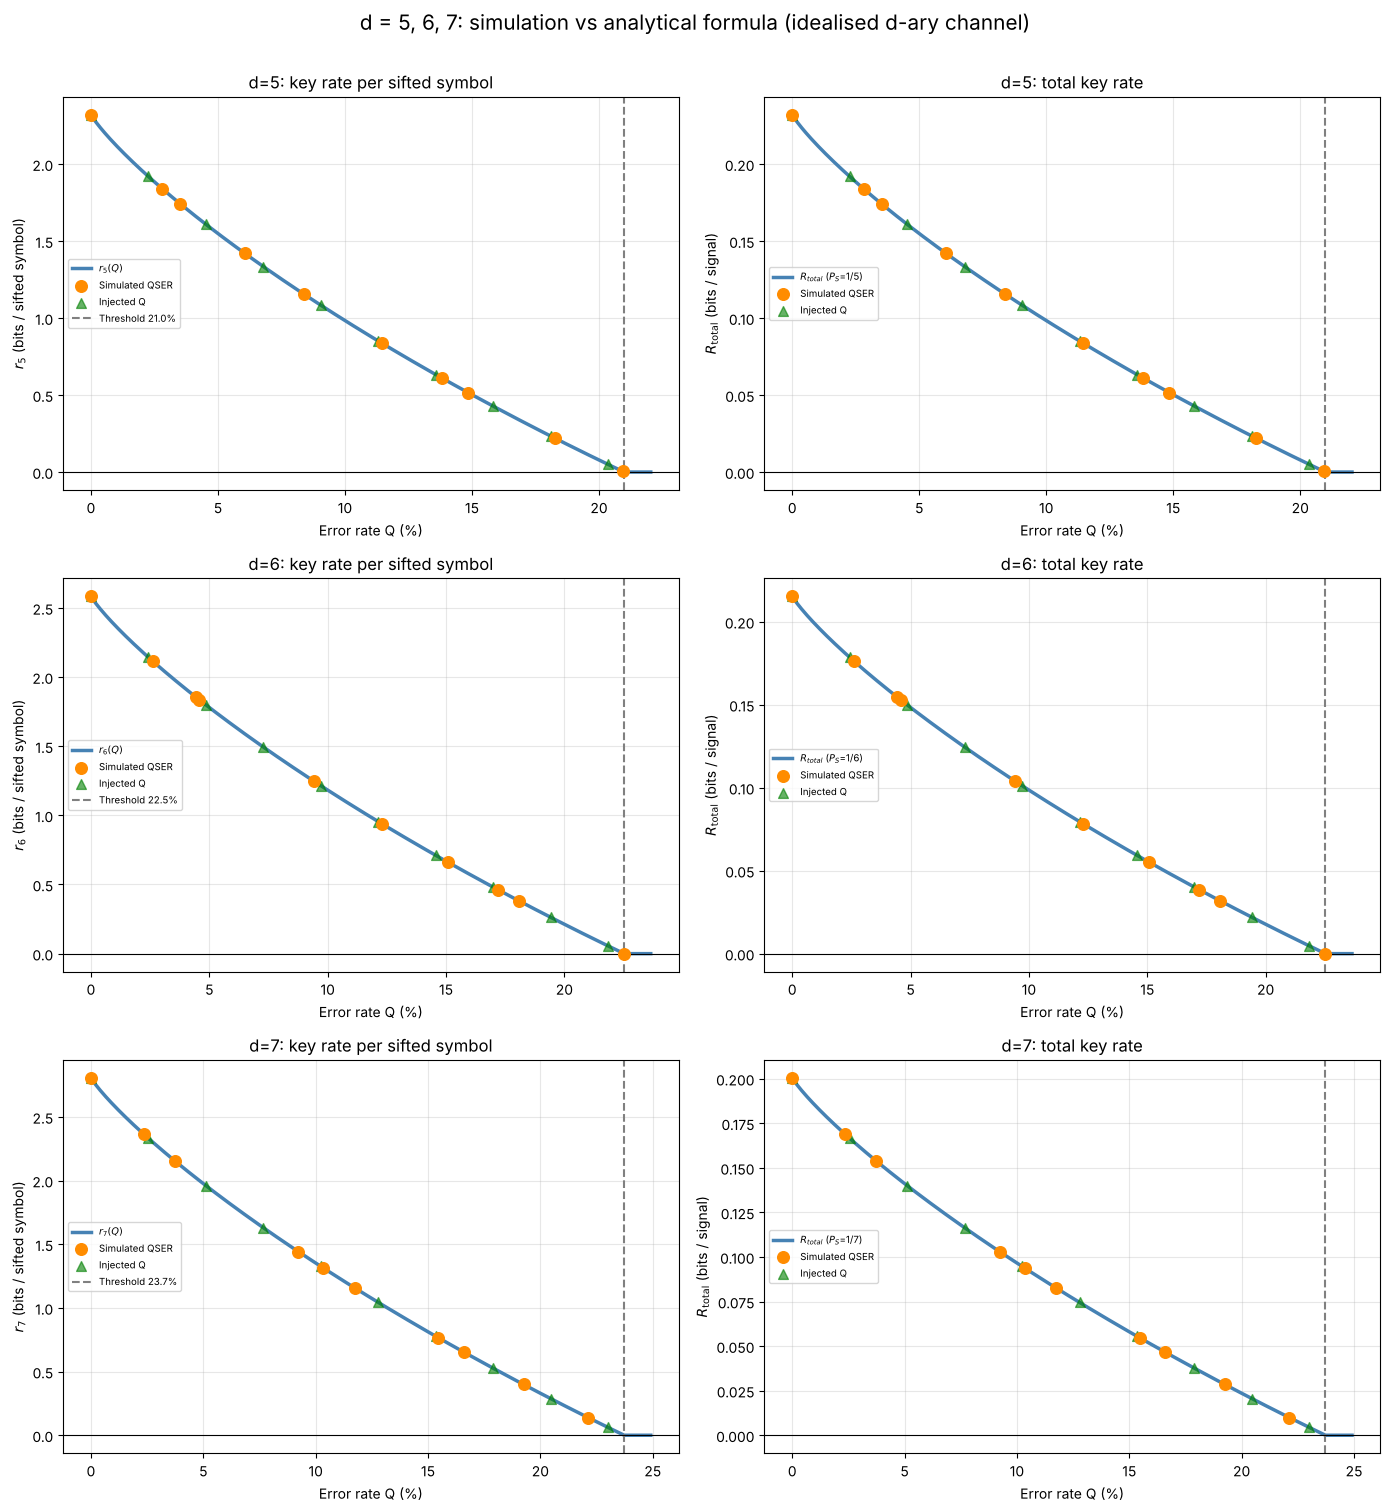

In [ ]:
fig, axes = plt.subplots(len(DIMENSIONS), 2, figsize=(14, 5 * len(DIMENSIONS)))
for row, d in enumerate(DIMENSIONS):
    df_d = sweep_qudit[d]
    Q_curve = np.linspace(0.001, thresholds[d] * 1.05, 400)

    ax = axes[row, 0]
    ax.plot(Q_curve * 100, [r_d_formula(Q, d) for Q in Q_curve], lw=2.5, color="steelblue", label=f"$r_{d}(Q)$")
    ax.scatter(df_d["Q_simulated"] * 100, df_d["r_at_Q_sim"], s=70, color="darkorange", zorder=5, label="Simulated QSER")
    ax.scatter(df_d["Q_injected"] * 100, df_d["r_at_Q_inj"], s=50, color="green", marker="^", alpha=0.6, zorder=4, label="Injected Q")
    ax.axvline(thresholds[d] * 100, color="gray", ls="--", label=f"Threshold {thresholds[d]*100:.1f}%")
    ax.axhline(0, color="black", lw=0.8)
    ax.set_xlabel("Error rate Q (%)"); ax.set_ylabel(f"$r_{d}$ (bits / sifted symbol)")
    ax.set_title(f"d={d}: key rate per sifted symbol"); ax.legend(fontsize=7); ax.grid(alpha=0.3)

    ax = axes[row, 1]
    ax.plot(Q_curve * 100, [R_total_formula(Q, d) for Q in Q_curve], lw=2.5, color="steelblue", label=f"$R_{{total}}$ ($P_S$=1/{d})")
    ax.scatter(df_d["Q_simulated"] * 100, df_d["R_at_Q_sim"], s=70, color="darkorange", zorder=5, label="Simulated QSER")
    ax.scatter(df_d["Q_injected"] * 100, df_d["R_at_Q_inj"], s=50, color="green", marker="^", alpha=0.6, zorder=4, label="Injected Q")
    ax.axvline(thresholds[d] * 100, color="gray", ls="--")
    ax.axhline(0, color="black", lw=0.8)
    ax.set_xlabel("Error rate Q (%)"); ax.set_ylabel(r"$R_{\rm total}$ (bits / signal)")
    ax.set_title(f"d={d}: total key rate"); ax.legend(fontsize=7); ax.grid(alpha=0.3)
plt.suptitle("d = 5, 6, 7: simulation vs analytical formula (idealised d-ary channel)", fontsize=15, y=1.005)
plt.tight_layout()
plt.show()

### Convergence check
With a fixed injected noise level, the simulated QSER fluctuates around it with standard deviation
$\approx\sqrt{Q(1-Q)/n}$, where $n$ is the number of sifted rounds. With zero injected noise the QSER
is exactly zero at any $N$, because the noiseless protocol is exact.

    N  Q_sim  error  n_sifted  sigma_expected
  500 0.0769 0.0031        26          0.0532
 1000 0.0833 0.0033        60          0.0350
 2000 0.0686 0.0114       102          0.0269
 4000 0.0628 0.0172       207          0.0189
 8000 0.0837 0.0037       406          0.0135
16000 0.0900 0.0100       811          0.0095

Zero-noise QSER at N = 15000:


  d=5: QSER = 0.0000  (sifted 739)


  d=6: QSER = 0.0000  (sifted 595)


  d=7: QSER = 0.0000  (sifted 542)


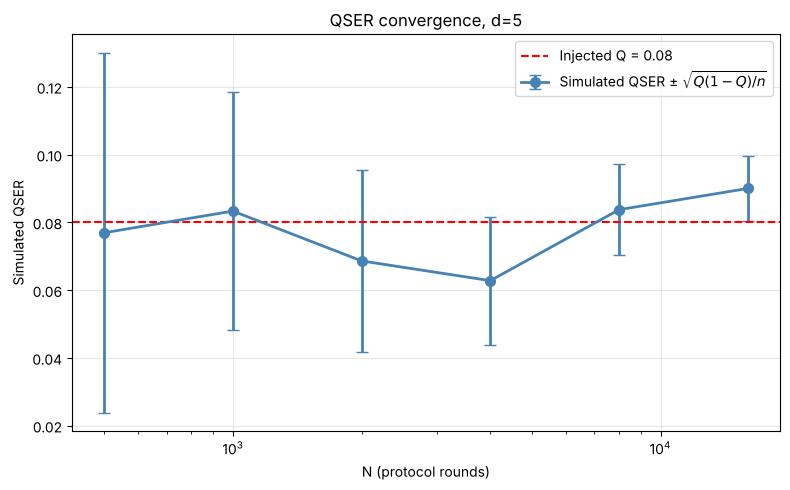

In [ ]:
d_test, Q_fixed = 5, 0.08
conv = []
for N in [500, 1000, 2000, 4000, 8000, 16000]:
    r = run_protocol_qudit(d_test, N, Q_noise=Q_fixed, seed=2024)
    conv.append({"N": N, "Q_sim": r["Q_sim"], "error": abs(r["Q_sim"] - Q_fixed), "n_sifted": r["key_sifted"],
                 "sigma_expected": np.sqrt(Q_fixed * (1 - Q_fixed) / max(r["key_sifted"], 1))})
df_conv = pd.DataFrame(conv)
print(df_conv.to_string(index=False, float_format="{:.4f}".format))

print("\nZero-noise QSER at N = 15000:")
for d in DIMENSIONS:
    r = run_protocol_qudit(d, 15000, seed=31415)
    print(f"  d={d}: QSER = {r['Q_sim']:.4f}  (sifted {r['key_sifted']})")

fig, ax = plt.subplots(figsize=(8, 5))
ax.errorbar(df_conv["N"], df_conv["Q_sim"], yerr=df_conv["sigma_expected"], fmt="o-", color="steelblue",
            capsize=4, lw=2, ms=7, label=r"Simulated QSER ± $\sqrt{Q(1-Q)/n}$")
ax.axhline(Q_fixed, color="red", ls="--", label=f"Injected Q = {Q_fixed}")
ax.set_xscale("log")
ax.set_xlabel("N (protocol rounds)"); ax.set_ylabel("Simulated QSER")
ax.set_title(f"QSER convergence, d={d_test}")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Protocol engine: physical depolarizing channel
The density-matrix circuit applies `DepolarizingChannel(p)` to every qubit of Alice's and Bob's
registers after preparation. Charlie measures the logical block with the Born rule
$p_i = \langle\Psi_i|\rho|\Psi_i\rangle$, and the outcome is sampled from that distribution. A round is
kept with probability equal to the trace of the logical block; the remainder is the erasure (leak) rate.

In [ ]:
def bsm_rho(logical_rho, bell_list, dist_idx):
    """Born-rule BSM on a (mixed) logical joint state; returns (success, m)."""
    probs = np.clip([float(np.real(np.vdot(bs, logical_rho @ bs))) for (_, _, bs) in bell_list], 0.0, None)
    probs = np.array(probs)
    p_success = probs[dist_idx].sum()
    if p_success <= 0.0 or np.random.random() > p_success:
        return False, None
    p_cond = probs[dist_idx] / p_success
    chosen = dist_idx[np.random.choice(len(dist_idx), p=p_cond)]
    return True, bell_list[chosen][1]


noisy_circuits = {}
for d in DIMENSIONS:
    nq, _ = setup_dimension(d)
    dev_mixed = qml.device("default.mixed", wires=2 * nq)

    def make_noisy_circuit(d=d, nq=nq, dev=dev_mixed):
        @qml.qnode(dev)
        def circuit(sym_a, basis_a, sym_b, basis_b, p_dep=0.0):
            qml.StatePrep(np.kron(padded_state(sym_a, d, nq, basis_a),
                                  padded_state(sym_b, d, nq, basis_b)), wires=range(2 * nq))
            if p_dep > 0.0:
                for w in range(2 * nq):
                    qml.DepolarizingChannel(p_dep, wires=w)
            return qml.density_matrix(wires=range(2 * nq))
        return circuit

    noisy_circuits[d] = make_noisy_circuit()


def run_protocol_channel_noise(d, N, p_dep=0.0, with_eve=False, seed=42):
    """Qudit MDI-QKD with depolarizing channel noise; returns QSER, sifted count and leak rate."""
    np.random.seed(seed)
    nq, _ = setup_dimension(d)
    bl, dist = bell_data[d]["bell_list"], bell_data[d]["DIST"]
    key_errors = key_sifted = leaked = 0
    alice_key, bob_key = [], []

    for _ in range(N):
        basis_a = np.random.randint(0, 2)
        basis_b = np.random.randint(0, 2)
        sym_a   = np.random.randint(0, d)
        sym_b   = np.random.randint(0, d)

        tx_basis, tx_sym = basis_a, sym_a
        if with_eve:
            e_basis = np.random.randint(0, 2)
            tx_sym  = sym_a if e_basis == basis_a else np.random.randint(0, d)
            tx_basis = e_basis

        rho = np.array(noisy_circuits[d](tx_sym, "comp" if tx_basis == 0 else "had",
                                         sym_b, "comp" if basis_b == 0 else "had", p_dep=p_dep))
        logical = extract_logical_rho(rho, d, nq)
        trace = float(np.real(np.trace(logical)))
        if trace < 1e-9 or np.random.random() > trace:
            leaked += 1                       # erasure: population outside the logical subspace
            continue

        ok, m = bsm_rho(logical / trace, bl, dist)
        if not ok or basis_a != basis_b or basis_a != 0:
            continue

        key_sifted += 1
        b_corr = (sym_b - m) % d
        key_errors += int(b_corr != sym_a)
        alice_key.append(sym_a)
        bob_key.append(b_corr)

    return {"Q_sim": key_errors / key_sifted if key_sifted else 0.0, "key_sifted": key_sifted,
            "leak_rate": leaked / N, "alice_key": alice_key, "bob_key": bob_key}


for d in DIMENSIONS:
    r0 = run_protocol_channel_noise(d, 1000, seed=1)
    assert r0["Q_sim"] == 0.0 and r0["leak_rate"] == 0.0
    r1 = run_protocol_channel_noise(d, 1500, p_dep=0.05, seed=2)
    print(f"d={d}: zero-noise QSER = 0, no leakage | p_dep=0.05: QSER={r1['Q_sim']:.4f}, leak rate={r1['leak_rate']:.3f}")

d=5: zero-noise QSER = 0, no leakage | p_dep=0.05: QSER=0.1250, leak rate=0.068


d=6: zero-noise QSER = 0, no leakage | p_dep=0.05: QSER=0.1695, leak rate=0.056


d=7: zero-noise QSER = 0, no leakage | p_dep=0.05: QSER=0.1346, leak rate=0.028


### Channel-noise sweep

In [ ]:
N_CHANNEL       = 1200
N_NOISE_CHANNEL = 6
P_DEP_MAX       = 0.045

sweep_channel = {}
t0 = time.time()
for d in DIMENSIONS:
    rows = []
    print(f"\nd={d} (depolarizing channel)")
    for i, p in enumerate(np.linspace(0.0, P_DEP_MAX, N_NOISE_CHANNEL)):
        r = run_protocol_channel_noise(d, N_CHANNEL, p_dep=p, seed=200 + i)
        rows.append({"p_dep": p, "Q_simulated": r["Q_sim"], "r_at_Q_sim": r_d_formula(r["Q_sim"], d),
                     "R_at_Q_sim": R_total_formula(r["Q_sim"], d), "key_sifted": r["key_sifted"],
                     "leak_rate": r["leak_rate"]})
        print(f"  p_dep={p:5.3f}  Q_sim={r['Q_sim']*100:5.2f}%  sifted={r['key_sifted']:4d}  leak={r['leak_rate']:.3f}")
    sweep_channel[d] = pd.DataFrame(rows)
print(f"\nChannel sweep time: {time.time() - t0:.1f} s")


d=5 (depolarizing channel)


  p_dep=0.000  Q_sim= 0.00%  sifted=  61  leak=0.000


  p_dep=0.009  Q_sim= 0.00%  sifted=  55  leak=0.012


  p_dep=0.018  Q_sim= 6.25%  sifted=  64  leak=0.029


  p_dep=0.027  Q_sim= 6.45%  sifted=  62  leak=0.042


  p_dep=0.036  Q_sim= 7.84%  sifted=  51  leak=0.045


... (9 outputs left out)

  p_dep=0.018  Q_sim= 5.13%  sifted=  39  leak=0.004


  p_dep=0.027  Q_sim=13.89%  sifted=  36  leak=0.010


  p_dep=0.036  Q_sim=11.11%  sifted=  45  leak=0.022


  p_dep=0.045  Q_sim=22.50%  sifted=  40  leak=0.022

Channel sweep time: 168.8 s


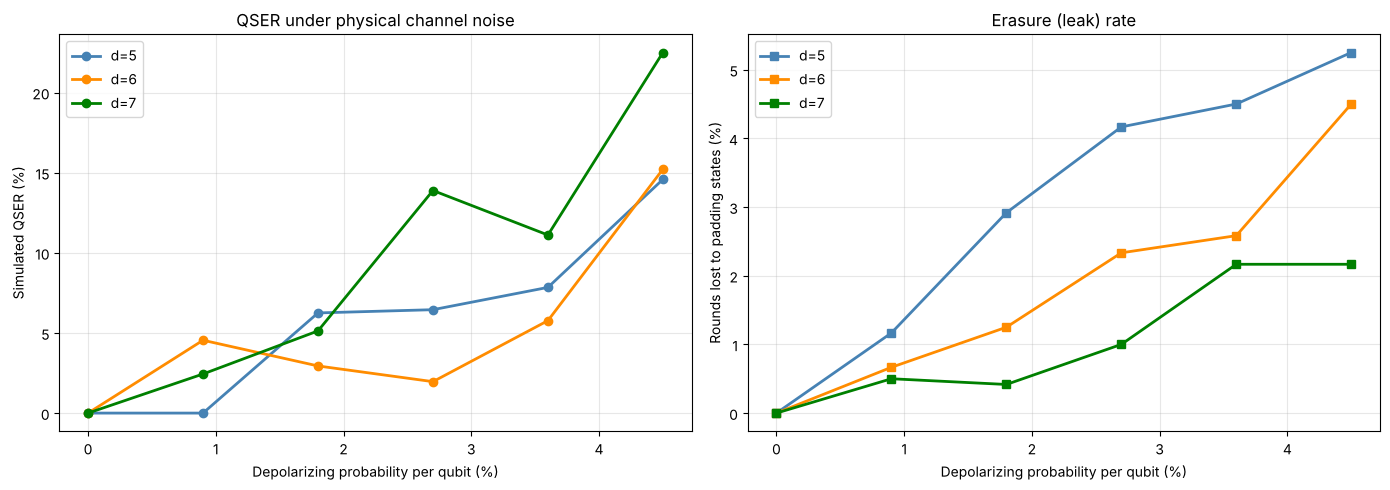

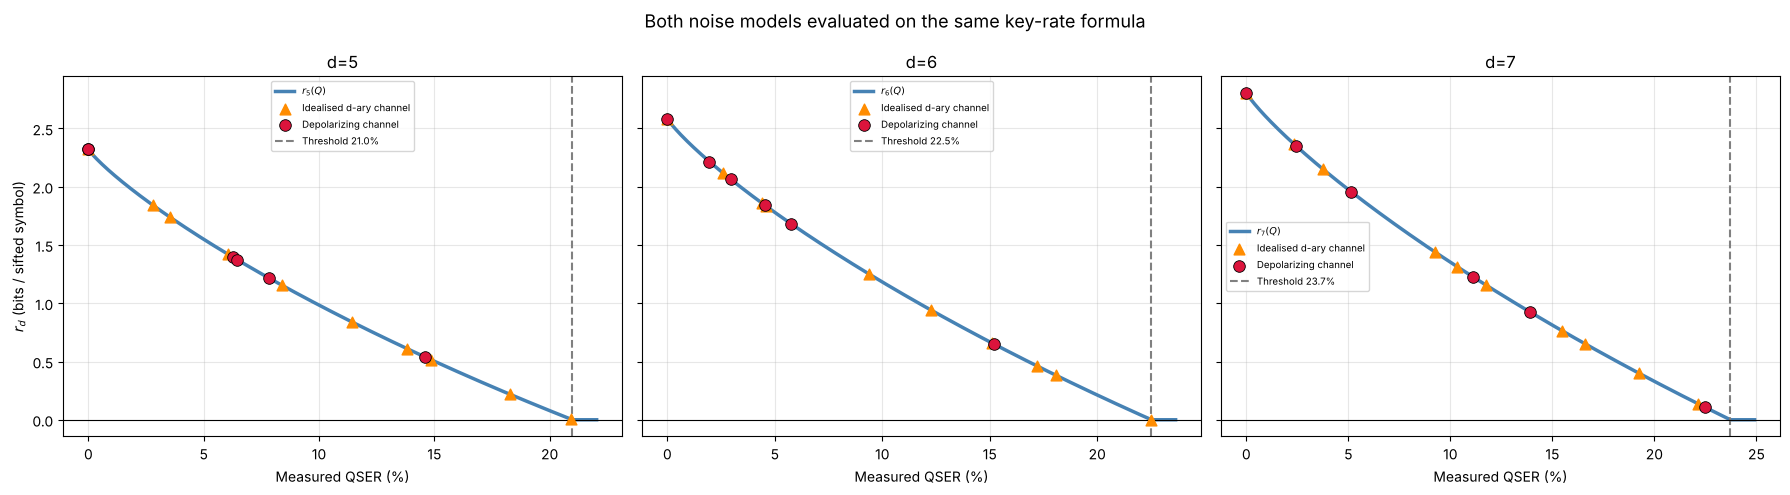

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for d, c in zip(DIMENSIONS, ["steelblue", "darkorange", "green"]):
    df_c = sweep_channel[d]
    axes[0].plot(df_c["p_dep"] * 100, df_c["Q_simulated"] * 100, "o-", color=c, lw=2, label=f"d={d}")
    axes[1].plot(df_c["p_dep"] * 100, df_c["leak_rate"] * 100, "s-", color=c, lw=2, label=f"d={d}")
axes[0].set_xlabel("Depolarizing probability per qubit (%)"); axes[0].set_ylabel("Simulated QSER (%)")
axes[0].set_title("QSER under physical channel noise"); axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].set_xlabel("Depolarizing probability per qubit (%)"); axes[1].set_ylabel("Rounds lost to padding states (%)")
axes[1].set_title("Erasure (leak) rate"); axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, len(DIMENSIONS), figsize=(6 * len(DIMENSIONS), 5), sharey=True)
for ax, d in zip(axes, DIMENSIONS):
    Q_curve = np.linspace(0.001, thresholds[d] * 1.05, 400)
    ax.plot(Q_curve * 100, [r_d_formula(Q, d) for Q in Q_curve], lw=2.5, color="steelblue", label=f"$r_{d}(Q)$")
    ax.scatter(sweep_qudit[d]["Q_simulated"] * 100, sweep_qudit[d]["r_at_Q_sim"], s=60, color="darkorange",
               marker="^", zorder=5, label="Idealised d-ary channel")
    ax.scatter(sweep_channel[d]["Q_simulated"] * 100, sweep_channel[d]["r_at_Q_sim"], s=70, color="crimson",
               edgecolor="black", lw=0.6, zorder=6, label="Depolarizing channel")
    ax.axvline(thresholds[d] * 100, color="gray", ls="--", label=f"Threshold {thresholds[d]*100:.1f}%")
    ax.axhline(0, color="black", lw=0.8)
    ax.set_xlabel("Measured QSER (%)"); ax.set_title(f"d={d}"); ax.grid(alpha=0.3); ax.legend(fontsize=7)
axes[0].set_ylabel("$r_d$ (bits / sifted symbol)")
plt.suptitle("Both noise models evaluated on the same key-rate formula", fontsize=13)
plt.tight_layout()
plt.show()

## 6. Cross-dimension analysis, d = 2–7 (and d = 8, 9 from the formulas)

Total key rate $R_{\rm total}(Q, d) = \frac{1}{2d}\, r_d(Q)$. The $1/d$ factor from the BSM success
probability makes the rate-optimal dimension depend on the operating noise level.

- Crossover $Q^*(d \to d+1)$: root of $R_{\rm total}(Q, d+1) = R_{\rm total}(Q, d)$, i.e. $(d+1)\,r_d = d\,r_{d+1}$.
- Security margin: $Q_{\rm Eve} - e^*(d)$ with $Q_{\rm Eve} = \tfrac12\cdot\tfrac{d-1}{d}$.

In [ ]:
DIMS_ALL = [2, 3, 4, 5, 6, 7]
DIMS_EXT = [2, 3, 4, 5, 6, 7, 8, 9]
COLORS_D = {2: "#0072B2", 3: "#E69F00", 4: "#7b2cbf", 5: "#3a86ff", 6: "#fb5607", 7: "#38b000"}

th_all = {d: zero_rate_threshold(d) for d in DIMS_EXT}


def crossover(d1, d2):
    """Noise level above which d2 overtakes d1 in total key rate (None if no crossing)."""
    f = lambda Q: r_d_raw(Q, d1) * d2 - r_d_raw(Q, d2) * d1
    hi = min(th_all[d1], th_all[d2]) - 1e-3
    return brentq(f, 1e-4, hi) if f(1e-4) * f(hi) < 0 else None


print("Total key rate at Q = 0 (bits / signal):")
print("  " + "  ".join(f"d={d}: {R_total_formula(0.0, d):.3f}" for d in DIMS_ALL))

table_rows, prev_th = [], None
for d in DIMS_EXT:
    q_eve = 0.5 * (d - 1) / d
    qc = crossover(d, d + 1) if d + 1 in th_all else None
    table_rows.append({"d": d, "e* (%)": th_all[d] * 100,
                       "Δe* (pp)": None if prev_th is None else (th_all[d] - prev_th) * 100,
                       "Q*(d→d+1) (%)": None if qc is None else qc * 100,
                       "Q_Eve (%)": q_eve * 100, "margin (pp)": (q_eve - th_all[d]) * 100})
    prev_th = th_all[d]
df_table = pd.DataFrame(table_rows)
print("\nDimensional trade-off (simulation covers d=2..7; d=8, 9 from the same equations):")
print(df_table.to_string(index=False, float_format="{:.2f}".format, na_rep="–"))

print("\nRate-optimal dimension vs operating QSER:")
Q_fine = np.arange(0.0, 0.16, 0.0005)
prev = None
for Q in Q_fine:
    best = DIMS_EXT[int(np.argmax([R_total_formula(Q, d) for d in DIMS_EXT]))]
    if best != prev:
        print(f"  from Q = {Q*100:5.2f}%: optimum d = {best}")
        prev = best

Total key rate at Q = 0 (bits / signal):
  d=2: 0.250  d=3: 0.264  d=4: 0.250  d=5: 0.232  d=6: 0.215  d=7: 0.201

Dimensional trade-off (simulation covers d=2..7; d=8, 9 from the same equations):
 d  e* (%)  Δe* (pp)  Q*(d→d+1) (%)  Q_Eve (%)  margin (pp)
 2   11.00         –              –      25.00        14.00
 3   15.95      4.94           2.96      33.33        17.39
 4   18.93      2.98           6.88      37.50        18.57
 5   20.99      2.06           9.87      40.00        19.01
 6   22.52      1.53          12.19      41.67        19.15
 7   23.72      1.20          14.03      42.86        19.13
 8   24.70      0.98          15.55      43.75        19.05
 9   25.52      0.82              –      44.44        18.93

Rate-optimal dimension vs operating QSER:
  from Q =  0.00%: optimum d = 3
  from Q =  3.00%: optimum d = 4
  from Q =  6.90%: optimum d = 5
  from Q =  9.90%: optimum d = 6
  from Q = 12.20%: optimum d = 7
  from Q = 14.05%: optimum d = 8
  from Q = 15.55%: opt

### Total key rate vs channel noise, d = 2–7
Solid lines are analytical. Markers are circuit-simulated points at the measured QSER: depolarizing-
channel sweeps for d = 2, 3, 4 and the physical depolarizing channel for d = 5, 6, 7.

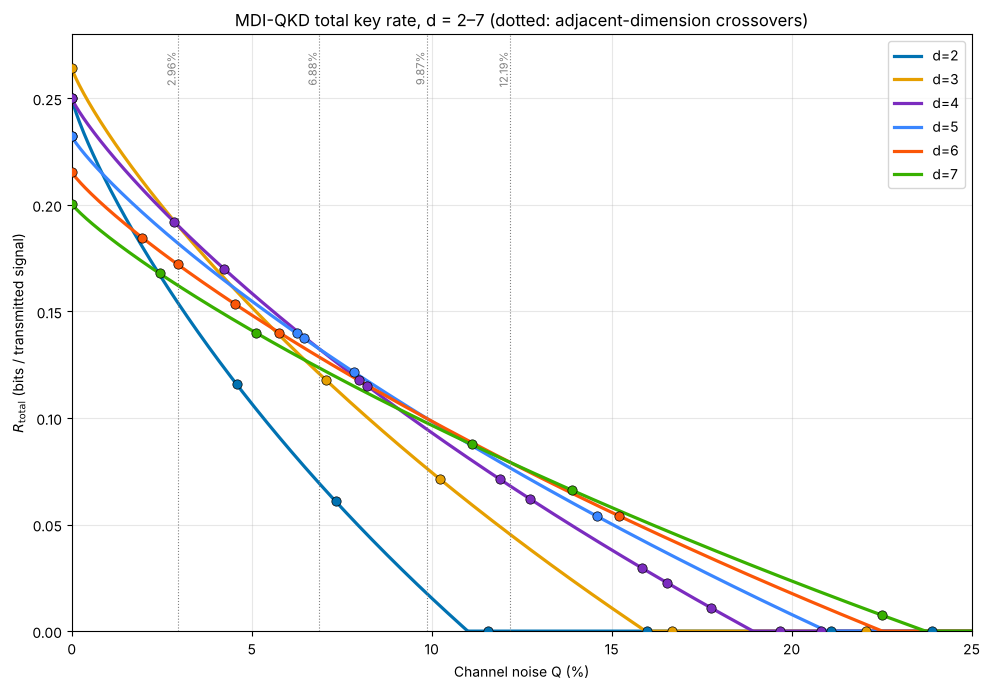

In [ ]:
sim_points = {2: sweep_d2[["Q_simulated"]].assign(R=[R_total_formula(q, 2) for q in sweep_d2["Q_simulated"]]),
              3: sweep_d3[["Q_simulated"]].assign(R=[R_total_formula(q, 3) for q in sweep_d3["Q_simulated"]]),
              4: sweep_d4[["Q_simulated", "R_at_Q_sim"]].rename(columns={"R_at_Q_sim": "R"})}
for d in DIMENSIONS:
    sim_points[d] = sweep_channel[d][["Q_simulated", "R_at_Q_sim"]].rename(columns={"R_at_Q_sim": "R"})

Q_plot = np.linspace(0.0, 0.25, 600)
fig, ax = plt.subplots(figsize=(10, 7))
for d in DIMS_ALL:
    ax.plot(Q_plot * 100, [R_total_formula(Q, d) for Q in Q_plot], lw=2.3, color=COLORS_D[d], label=f"d={d}")
    pts = sim_points[d][sim_points[d]["Q_simulated"] <= 0.25]
    ax.scatter(pts["Q_simulated"] * 100, pts["R"], color=COLORS_D[d], s=45, edgecolor="black", lw=0.5, zorder=5)
for d in range(3, 7):
    qc = crossover(d, d + 1)
    ax.axvline(qc * 100, color="gray", lw=0.8, ls=":")
    ax.text(qc * 100, 0.272, f"{qc*100:.2f}%", rotation=90, fontsize=8, ha="right", va="top", color="gray")
ax.set_xlabel("Channel noise Q (%)"); ax.set_ylabel(r"$R_{\rm total}$ (bits / transmitted signal)")
ax.set_title("MDI-QKD total key rate, d = 2–7 (dotted: adjacent-dimension crossovers)")
ax.set_xlim(0, 25); ax.set_ylim(0, 0.28)
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Marginal gain and diminishing returns

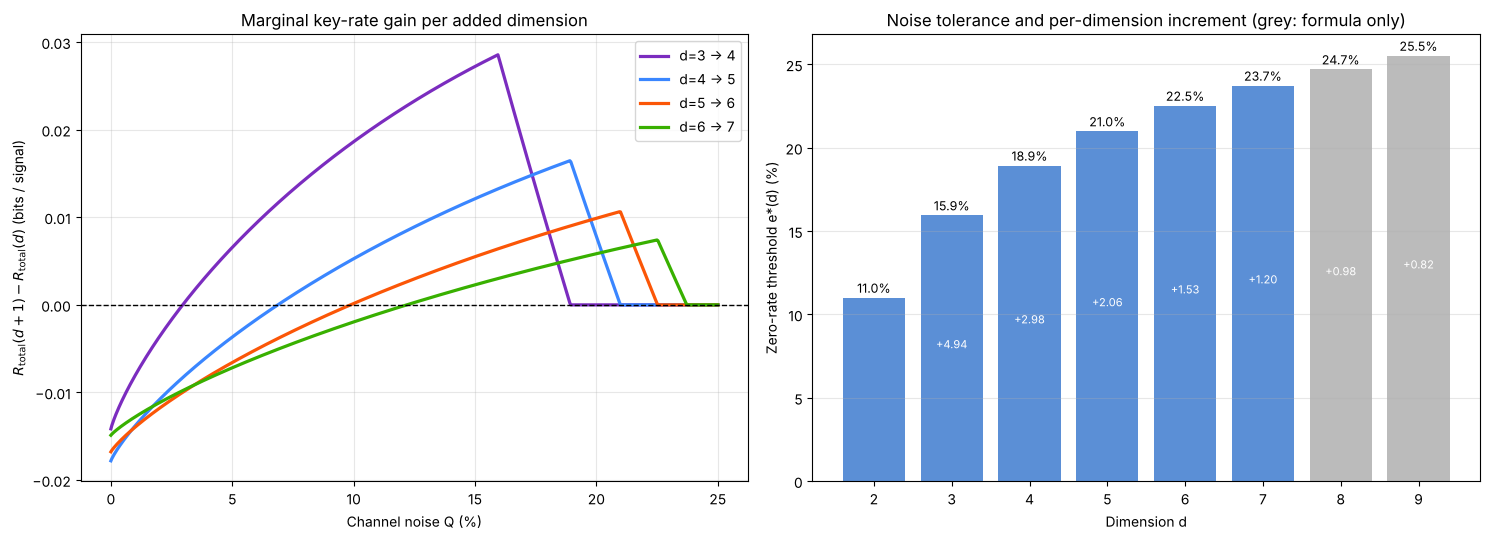

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
ax = axes[0]
for d in range(3, 7):
    gain = [R_total_formula(Q, d + 1) - R_total_formula(Q, d) for Q in Q_plot]
    ax.plot(Q_plot * 100, gain, lw=2.3, color=COLORS_D[d + 1], label=f"d={d} → {d+1}")
ax.axhline(0, color="black", lw=1, ls="--")
ax.set_xlabel("Channel noise Q (%)"); ax.set_ylabel(r"$R_{\rm total}(d+1) - R_{\rm total}(d)$ (bits / signal)")
ax.set_title("Marginal key-rate gain per added dimension"); ax.legend(); ax.grid(alpha=0.3)

ax = axes[1]
th_vals = [th_all[d] * 100 for d in DIMS_EXT]
bars = ax.bar(DIMS_EXT, th_vals, color=["#5b8fd6" if d <= 7 else "#bbbbbb" for d in DIMS_EXT])
for b, t in zip(bars, th_vals):
    ax.text(b.get_x() + b.get_width() / 2, t + 0.3, f"{t:.1f}%", ha="center", fontsize=9)
for i in range(1, len(DIMS_EXT)):
    ax.annotate(f"+{th_vals[i] - th_vals[i-1]:.2f}", xy=(DIMS_EXT[i], th_vals[i] / 2), ha="center", fontsize=8, color="white")
ax.set_xlabel("Dimension d"); ax.set_ylabel("Zero-rate threshold e*(d) (%)")
ax.set_title("Noise tolerance and per-dimension increment (grey: formula only)")
ax.set_xticks(DIMS_EXT); ax.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.show()

### Total-key-rate heatmap and optimal-dimension ladder
The colour shows $R_{\rm total}(Q, d)$. White dots mark the rate-optimal dimension at each noise level,
which rises with $Q$. The red line is the security margin $Q_{\rm Eve} - e^*(d)$, which peaks at $d = 6$.

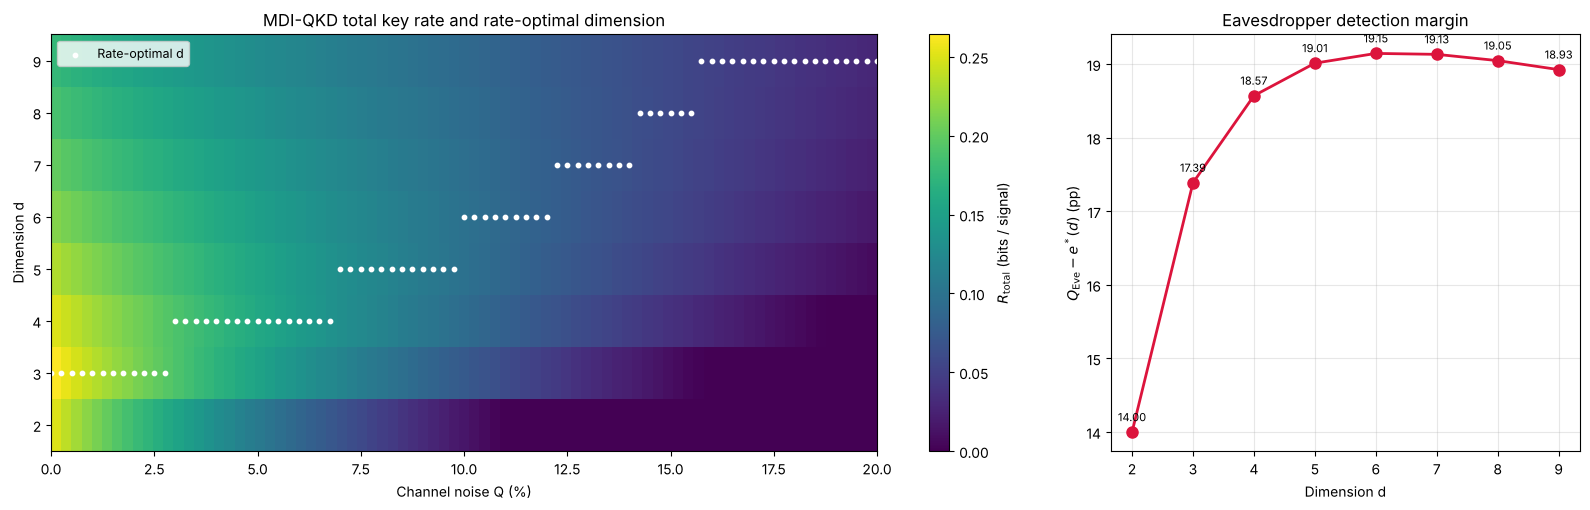

In [ ]:
Q_hm = np.linspace(0.0, 0.20, 81)
R_hm = np.array([[R_total_formula(Q, d) for Q in Q_hm] for d in DIMS_EXT])
best_hm = [DIMS_EXT[int(np.argmax(R_hm[:, j]))] for j in range(len(Q_hm))]

fig, axes = plt.subplots(1, 2, figsize=(16, 5.2), gridspec_kw={"width_ratios": [2.2, 1]})
ax = axes[0]
im = ax.imshow(R_hm, aspect="auto", origin="lower", cmap="viridis",
               extent=[Q_hm[0] * 100, Q_hm[-1] * 100, DIMS_EXT[0] - 0.5, DIMS_EXT[-1] + 0.5])
ax.scatter(Q_hm * 100, best_hm, color="white", s=10, label="Rate-optimal d")
fig.colorbar(im, ax=ax, label=r"$R_{\rm total}$ (bits / signal)")
ax.set_xlabel("Channel noise Q (%)"); ax.set_ylabel("Dimension d"); ax.set_yticks(DIMS_EXT)
ax.set_title("MDI-QKD total key rate and rate-optimal dimension"); ax.legend(loc="upper left", fontsize=9)

ax = axes[1]
ax.plot(df_table["d"], df_table["margin (pp)"], "o-", color="crimson", lw=2, ms=8)
for d, mg in zip(df_table["d"], df_table["margin (pp)"]):
    ax.text(d, mg + 0.15, f"{mg:.2f}", ha="center", fontsize=8)
ax.set_xlabel("Dimension d"); ax.set_ylabel(r"$Q_{\rm Eve} - e^*(d)$ (pp)")
ax.set_title("Eavesdropper detection margin"); ax.set_xticks(DIMS_EXT); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()